# Missing Data and Statistical Inference

**Question.** When some values are missing, how much does the way we handle them change a regression estimate — and how far can we trust its confidence interval?

**Set-up.** The data are simulated from a known model, so the right answer is known:

`Y = 5 + 2·X1 − 1.5·X2 + 1·X3 + ε`  — the focus is **β₁ = 2**.

About 20% of the values of **Y** and of **X1** are then deleted under three missingness mechanisms (**MCAR, MAR, MNAR**), and the regression is re-estimated after handling the gaps in eight different ways.

| Method | What it does | Uses Z? |
|---|---|---|
| Complete Case | drop every row that has a missing value | no |
| Mean Imputation | fill each gap with the column mean | no |
| Hot-Deck | copy the value from the most similar complete row | yes |
| Regression Imputation | fill each gap with its predicted value | yes |
| Stochastic Regression | predicted value + a random residual | yes |
| MICE (normal) | several random regression imputations, combined with Rubin's rules | yes |
| MICE (PMM) | same, but the filled-in values are real values borrowed from similar rows | yes |
| EM | maximum likelihood for the means and covariances of all variables | yes |

**Z is an auxiliary variable**: a noisy copy of Y (`Z = Y + noise`). It is *not* in the regression model, but it is observed for everyone and can help to fill in the gaps.

**How the comparison is organised.** Everything is compared **within each missingness mechanism**: for MCAR, then MAR, then MNAR we ask *which way of handling the gaps works best?* (We do not rank the mechanisms against each other — each one is its own setting.) All results, tables and figures are therefore grouped one mechanism at a time.

**How the notebook is organised — every step is its own block**

1. Setup
2. Simulate the complete data
3. The analysis model (the regression every method ends with)
4. Create the missing data: MCAR, MAR, MNAR
5. **Part A — one worked example.** Each method gets its own section: *define → apply to MCAR → apply to MAR → apply to MNAR → standard error*. It ends with tables and figures **one mechanism at a time**.
6. **Part B — simulation study.** The whole experiment repeated many times (`N_REPS`, default 300) with fresh data. This is the main evidence, because one dataset cannot separate a method's real behaviour from luck. Again, tables and figures **one mechanism at a time**.
7. Master tables, the best method per mechanism, and interpretation
8. Limitations · 9. Conclusion

## 1. Setup

In [1]:
# ===== Step 1a — Libraries =====
# If a package is missing, uncomment the next line:
# !pip install numpy pandas scipy scikit-learn statsmodels matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from sklearn.impute import KNNImputer
from IPython.display import display, Markdown

In [2]:
# ===== Step 1b — Settings you can change =====
SEED = 42                                      # every random block starts from this seed, so any block can be re-run alone
N = 200                                        # observations per dataset
TRUE_BETA = np.array([5.0, 2.0, -1.5, 1.0])    # intercept, X1, X2, X3
M_IMPUTATIONS = 10                             # number of imputed datasets in MICE
B_BOOT = 500                                   # bootstrap samples in Part A
N_REPS = 300                                   # repetitions in Part B (300 takes a few minutes; 50 = quick test)
EM_BOOT = 40                                   # small bootstrap for EM's standard error inside Part B

MECHANISMS = ["MCAR", "MAR", "MNAR"]
METHOD_ORDER = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation",
                "Stochastic Regression", "MICE (normal)", "MICE (PMM)", "EM"]

## 2. Simulating the complete data

* **X1, X2, X3** are independent standard normal.
* **Y** follows the model above with N(0, 1) noise.
* **Z = Y + noise** is the auxiliary variable (never in the regression, never missing).

In [3]:
# ===== Step 2a — Function that creates one complete dataset =====
def make_data(rng, n=N):
    """One complete dataset: predictors X1-X3, outcome Y, auxiliary variable Z."""
    X = rng.normal(size=(n, 3))
    Y = TRUE_BETA[0] + X @ TRUE_BETA[1:] + rng.normal(size=n)
    Z = Y + rng.normal(size=n)                      # noisy copy of Y (not part of the regression)
    return pd.DataFrame(np.column_stack([X, Z, Y]), columns=["X1", "X2", "X3", "Z", "Y"])

In [4]:
# ===== Step 2b — Create the complete dataset used throughout Part A =====
rng = np.random.default_rng(SEED)
full = make_data(rng)

print("Shape:", full.shape)
full.head()

Shape: (200, 5)


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,0.066031,1.127241,0.467509,4.559425,3.272094


In [5]:
# ===== Step 2c — Summary statistics =====
full.describe().round(2)

,X1,X2,X3,Z,Y
count,200.00,200.00,200.00,200.00,200.00
mean,-0.00,-0.08,0.00,5.04,5.07
std,1.01,0.97,0.94,2.91,2.72
min,-2.96,-2.41,-2.57,-1.49,-1.79
25%,-0.71,-0.80,-0.60,2.82,3.03
50%,-0.07,-0.08,0.13,4.83,4.96
75%,0.67,0.46,0.54,7.19,6.97
max,2.33,2.91,2.91,13.12,12.73


In [6]:
# ===== Step 2d — Correlations (note how strongly Z follows Y) =====
full.corr().round(2)

,X1,X2,X3,Z,Y
X1,1.00,0.05,-0.08,0.68,0.70
X2,0.05,1.00,0.07,-0.43,-0.48
X3,-0.08,0.07,1.00,0.17,0.23
Z,0.68,-0.43,0.17,1.00,0.94
Y,0.70,-0.48,0.23,0.94,1.00


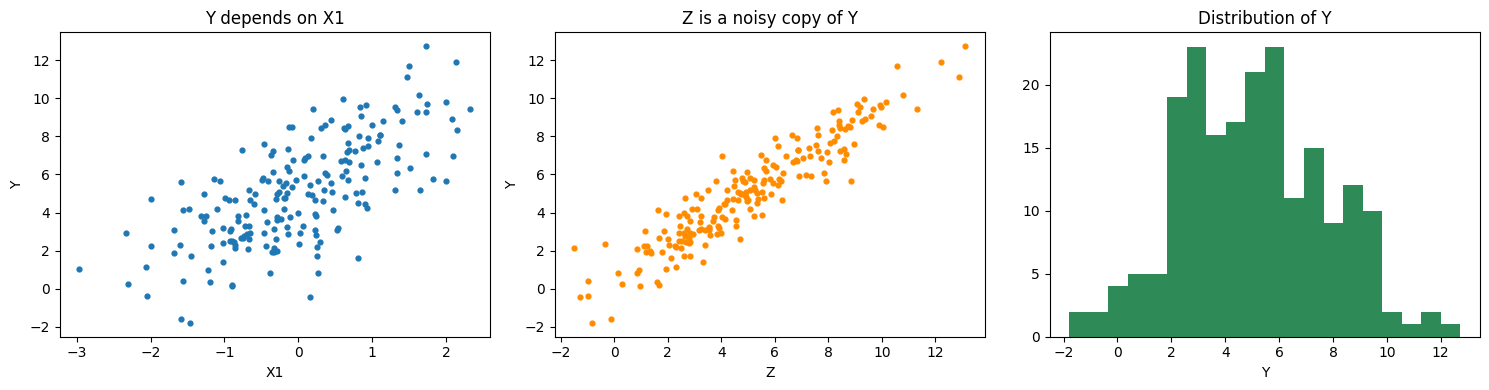

In [7]:
# ===== Step 2e — Look at the data =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(full["X1"], full["Y"], s=12)
axes[0].set_xlabel("X1"); axes[0].set_ylabel("Y"); axes[0].set_title("Y depends on X1")

axes[1].scatter(full["Z"], full["Y"], s=12, color="darkorange")
axes[1].set_xlabel("Z"); axes[1].set_ylabel("Y"); axes[1].set_title("Z is a noisy copy of Y")

axes[2].hist(full["Y"], bins=20, color="seagreen")
axes[2].set_xlabel("Y"); axes[2].set_title("Distribution of Y")

plt.tight_layout()
plt.show()

## 3. The analysis model

Every method ends in the same regression of **Y on X1, X2, X3**. The helper below returns the coefficients and their standard errors, both ordered `[intercept, X1, X2, X3]`.

In [8]:
# ===== Step 3a — The regression helper =====
def ols(d):
    """Least squares of Y on X1, X2, X3. Returns (coefficients, standard errors).
    The rows must have no missing values."""
    A = np.column_stack([np.ones(len(d)), d[["X1", "X2", "X3"]].to_numpy()])
    y = d["Y"].to_numpy()
    AtA_inv = np.linalg.inv(A.T @ A)
    beta = AtA_inv @ A.T @ y
    resid = y - A @ beta
    sigma2 = resid @ resid / (len(y) - A.shape[1])
    return beta, np.sqrt(sigma2 * np.diag(AtA_inv))

In [9]:
# ===== Step 3b — Check the helper against statsmodels =====
sm_fit = sm.OLS(full["Y"], sm.add_constant(full[["X1", "X2", "X3"]])).fit()
beta_check, se_check = ols(full)
print("ols() matches statsmodels:", np.allclose(beta_check, sm_fit.params) and np.allclose(se_check, sm_fit.bse))
print()
print(sm_fit.summary().tables[1])

ols() matches statsmodels: True

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.9629      0.073     68.376      0.000       4.820       5.106
X1             2.0368      0.072     28.216      0.000       1.894       2.179
X2            -1.5076      0.075    -20.129      0.000      -1.655      -1.360
X3             0.9483      0.078     12.217      0.000       0.795       1.101


In [10]:
# ===== Step 3c — Baseline: the regression on the complete data (nothing missing) =====
beta_full, se_full = ols(full)

baseline = pd.DataFrame({"true value": TRUE_BETA, "full-data estimate": beta_full, "SE": se_full},
                        index=["intercept", "X1", "X2", "X3"])
display(baseline.round(3))
print(f"Full-data estimate of beta1: {beta_full[1]:.3f}   (true value 2)")
print("This is the best any method can hope to match: it is what we would get if nothing were missing.")

,true value,full-data estimate,SE
intercept,5.0,4.963,0.073
X1,2.0,2.037,0.072
X2,-1.5,-1.508,0.075
X3,1.0,0.948,0.078


Full-data estimate of beta1: 2.037   (true value 2)
This is the best any method can hope to match: it is what we would get if nothing were missing.


## 4. Creating the missing data

About **20% of the values of Y and of X1** are deleted. The chance that a value is deleted depends on the mechanism:

* **MCAR** (missing completely at random) – 20% for everyone, pure luck.
* **MAR** (missing at random) – depends on **Z**, which is always observed. Because Z is related to Y, complete-case analysis is distorted, but methods that use Z can correct for it.
* **MNAR** (missing not at random) – depends on the **value itself** (large Y and large X1 are more likely to vanish). Nothing in the observed data reveals this, so no method can fully repair it.

For MAR and MNAR the chance is `expit(−2.23 + 2 × standardised driver)`; the intercept is tuned so that about 20% goes missing in every mechanism.

In [11]:
# ===== Step 4a — Helper, and the MCAR deletion rule =====
def standardize(s):
    """Rescale to mean 0 and standard deviation 1."""
    return (s - s.mean()) / s.std()


def delete_mcar(full, rng):
    """MCAR: every value of Y and X1 has the same 20% chance of being deleted."""
    data = full.copy()
    for col in ["Y", "X1"]:
        data.loc[rng.random(len(full)) < 0.20, col] = np.nan
    return data

In [12]:
# ===== Step 4b — The MAR deletion rule =====
def delete_mar(full, rng):
    """MAR: the chance of deletion depends on Z, which is always observed."""
    data = full.copy()
    prob = expit(-2.23 + 2.0 * standardize(full["Z"]))          # larger Z -> more likely to be deleted
    for col in ["Y", "X1"]:
        data.loc[rng.random(len(full)) < prob, col] = np.nan
    return data

In [13]:
# ===== Step 4c — The MNAR deletion rule =====
def delete_mnar(full, rng):
    """MNAR: the chance of deletion depends on the very value that gets deleted."""
    data = full.copy()
    for col in ["Y", "X1"]:
        prob = expit(-2.23 + 2.0 * standardize(full[col]))      # larger value -> more likely to be deleted
        data.loc[rng.random(len(full)) < prob, col] = np.nan
    return data

In [14]:
# ===== Step 4d — One function that applies any of the three rules =====
def make_missing(full, mechanism, rng):
    rules = {"MCAR": delete_mcar, "MAR": delete_mar, "MNAR": delete_mnar}
    return rules[mechanism](full, rng)

In [15]:
# ===== Step 4e — Create the MCAR dataset =====
rng = np.random.default_rng(SEED)
df_mcar = make_missing(full, "MCAR", rng)

print("Missing values per column:")
print(df_mcar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mcar.isna().any(axis=1).sum()} of {len(df_mcar)}")
df_mcar.head(8)

Missing values per column:
X1    45
X2     0
X3     0
Z      0
Y     43

Rows with at least one gap: 78 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,NaN,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,NaN
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [16]:
# ===== Step 4f — Create the MAR dataset =====
rng = np.random.default_rng(SEED)
df_mar = make_missing(full, "MAR", rng)

print("Missing values per column:")
print(df_mar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mar.isna().any(axis=1).sum()} of {len(df_mar)}")
df_mar.head(8)

Missing values per column:
X1    39
X2     0
X3     0
Z      0
Y     40

Rows with at least one gap: 61 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,7.927964
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,3.272094
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [17]:
# ===== Step 4g — Create the MNAR dataset =====
rng = np.random.default_rng(SEED)
df_mnar = make_missing(full, "MNAR", rng)

print("Missing values per column:")
print(df_mnar.isna().sum().to_string())
print(f"\nRows with at least one gap: {df_mnar.isna().any(axis=1).sum()} of {len(df_mnar)}")
df_mnar.head(8)

Missing values per column:
X1    41
X2     0
X3     0
Z      0
Y     41

Rows with at least one gap: 65 of 200


,X1,X2,X3,Z,Y
0,0.304717,-1.039984,0.750451,7.590227,8.435272
1,0.940565,-1.951035,-1.302180,6.844265,NaN
2,0.127840,-0.316243,-0.016801,7.332296,6.987691
3,-0.853044,0.879398,0.777792,2.504300,2.125020
4,NaN,1.127241,0.467509,4.559425,3.272094
5,-0.859292,0.368751,-0.958883,3.410518,2.310538
6,NaN,-0.049926,-0.184862,7.277625,7.409854
7,-0.680930,1.222541,-0.154529,0.853693,2.097899


In [18]:
# ===== Step 4h — Collect the three datasets and compare how much is missing =====
datasets = {"MCAR": df_mcar, "MAR": df_mar, "MNAR": df_mnar}

missing_counts = pd.DataFrame({mech: d.isna().sum() for mech, d in datasets.items()})
missing_counts.loc["rows with any gap"] = [d.isna().any(axis=1).sum() for d in datasets.values()]
missing_counts

,MCAR,MAR,MNAR
X1,45,39,41
X2,0,0,0
X3,0,0,0
Z,0,0,0
Y,43,40,41
rows with any gap,78,61,65


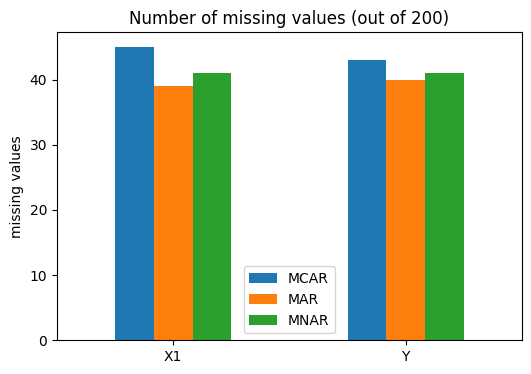

In [19]:
# ===== Step 4i — Bar chart of the missing counts =====
missing_counts.loc[["X1", "Y"]].plot.bar(figsize=(6, 4), rot=0)
plt.title("Number of missing values (out of %d)" % N)
plt.ylabel("missing values")
plt.show()

In [20]:
# ===== Step 4j — Check that the three mechanisms behave as designed =====
# Done on a very large dataset so that the pattern is not hidden by noise.
big = make_data(np.random.default_rng(1), n=20_000)

rows = []
for mech in MECHANISMS:
    d = make_missing(big, mech, np.random.default_rng(2))
    gone = d["Y"].isna()
    rows.append({
        "Mechanism": mech,
        "Y missing %": 100 * gone.mean(),
        "X1 missing %": 100 * d["X1"].isna().mean(),
        "Rows with any gap %": 100 * d.isna().any(axis=1).mean(),
        "Z gap": big["Z"][gone].mean() - big["Z"][~gone].mean(),
        "Y gap": big["Y"][gone].mean() - big["Y"][~gone].mean(),
    })
pd.DataFrame(rows).set_index("Mechanism").round(2)

,Y missing %,X1 missing %,Rows with any gap %,Z gap,Y gap
Mechanism,,,,,
MCAR,20.11,20.02,36.10,-0.01,-0.03
MAR,19.87,20.16,30.58,3.96,3.53
MNAR,19.82,20.08,32.28,3.74,3.72


*Gap* = average value among rows where Y went missing minus the average among the others. Under MCAR both gaps are about zero. Under MAR and MNAR, rows with a missing Y have higher Z and higher Y. (We can only see the Y gap because we deleted the values ourselves; in real data it is invisible — which is why MAR and MNAR cannot be told apart from the observed data alone.)

# Part A — one worked example

One complete dataset (`full`, seed 42) has been damaged three ways (`df_mcar`, `df_mar`, `df_mnar`). In this part every method is applied to each of them, step by step.

Every method gets its own section with the same steps:

* **a – define** the method as a small function
* **b, c, d – apply** it to the MCAR, MAR and MNAR datasets and look at what it did
* **e – standard error:** a bootstrap (resample the rows and repeat the *whole* method, imputation included) for single-imputation methods, or Rubin's rules for MICE

Two kinds of error are reported at the end:
* **Bias vs truth** = estimate − 2. This mixes the damage done by missing data with plain sampling noise.
* **Diff vs full data** = estimate − the estimate from the *same dataset before anything was deleted*. This isolates the damage done by the missing data.

## 5.1 Helpers for Part A

In [21]:
# ===== Step 5.1a — Where Part A keeps its results =====
estimates = {}    # estimates[(method, mechanism)] = (coefficients, "naive" standard errors)
intervals = {}    # intervals[(method, mechanism)] = (final SE of beta1, CI lower, CI upper)


def show_estimate(method, mech):
    beta, se = estimates[(method, mech)]
    se_text = "n/a" if se is None else f"{se[1]:.3f}"
    print(f"{method} | {mech}:  beta1 = {beta[1]:.3f}   naive SE = {se_text}   "
          f"(difference from the full-data fit: {beta[1] - beta_full[1]:+.3f})")


def show_interval(method, mech):
    se, low, high = intervals[(method, mech)]
    print(f"{method} | {mech}:  final SE = {se:.3f}   95% CI = ({low:.3f}, {high:.3f})")

In [22]:
# ===== Step 5.1b — Peek at what a method filled in =====
def peek(data, filled, truth, col="Y", n=5):
    """The first n deleted values of `col`: the true value next to what the method filled in."""
    gone = data[col].isna()
    table = pd.DataFrame({"true value": truth.loc[gone, col], "filled in": filled.loc[gone, col]})
    return table.head(n).round(2)

In [23]:
# ===== Step 5.1c — The bootstrap =====
def bootstrap(method, data, rng, B):
    """Resample the rows B times and redo the WHOLE method on each resample.
    Returns a B x 4 array with the four coefficients of every resample."""
    estimates_ = []
    for _ in range(B):
        resample = data.iloc[rng.integers(0, len(data), len(data))].reset_index(drop=True)
        estimates_.append(method(resample, rng)[0])
    return np.array(estimates_)


def boot_summary(boot_estimates):
    """Bootstrap standard error and 95% percentile interval for beta1."""
    b1 = boot_estimates[:, 1]
    return b1.std(ddof=1), np.percentile(b1, 2.5), np.percentile(b1, 97.5)

## 5.2 Method 1 — Complete case

**Idea:** delete every row that has any gap, then run the regression on what is left.

**Good:** simple, and unbiased when the data are MCAR. **Bad:** it throws away information (about a third of the rows here), and it is biased when missingness is related to the outcome (MAR through Z, and MNAR).

**Standard error:** bootstrap.

In [24]:
# ===== Step 5.2a — Complete case: the method =====
def drop_incomplete(data, rng):
    """Remove every row that has at least one missing value."""
    return data.dropna()


def complete_case(data, rng):
    """Complete-case analysis = drop the incomplete rows, then run the regression."""
    return ols(drop_incomplete(data, rng))

In [25]:
# ===== Step 5.2b — Complete case: MCAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mcar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mcar)}  ({len(df_mcar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MCAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MCAR")

Rows kept: 122 of 200  (78 rows discarded)


Complete Case | MCAR:  beta1 = 2.098   naive SE = 0.092   (difference from the full-data fit: +0.061)


In [26]:
# ===== Step 5.2c — Complete case: MAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mar)}  ({len(df_mar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MAR")

Rows kept: 139 of 200  (61 rows discarded)
Complete Case | MAR:  beta1 = 1.844   naive SE = 0.105   (difference from the full-data fit: -0.193)


In [27]:
# ===== Step 5.2d — Complete case: MNAR dataset =====
rng = np.random.default_rng(SEED)

kept = drop_incomplete(df_mnar, rng)                                  # 1. throw away the incomplete rows
print(f"Rows kept: {len(kept)} of {len(df_mnar)}  ({len(df_mnar) - len(kept)} rows discarded)")

estimates[("Complete Case", "MNAR")] = ols(kept)                 # 2. regression on the remaining rows
show_estimate("Complete Case", "MNAR")

Rows kept: 135 of 200  (65 rows discarded)
Complete Case | MNAR:  beta1 = 2.015   naive SE = 0.115   (difference from the full-data fit: -0.022)


In [28]:
# ===== Step 5.2e — Complete case: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(complete_case, data, rng, B_BOOT)
    intervals[("Complete Case", mech)] = boot_summary(boot_estimates)
    show_interval("Complete Case", mech)

Complete Case | MCAR:  final SE = 0.094   95% CI = (1.899, 2.265)


Complete Case | MAR:  final SE = 0.102   95% CI = (1.629, 2.053)


Complete Case | MNAR:  final SE = 0.103   95% CI = (1.834, 2.229)


## 5.3 Method 2 — Mean imputation

**Idea:** replace every gap by the mean of the observed values in that column.

**Problem:** every filled-in value sits exactly at the mean, so the variation in Y and X1 shrinks and the relationship between them weakens (the slope is pulled towards zero). The filled-in values are also treated as real data, so the standard error is too small.

**Standard error:** bootstrap.

In [29]:
# ===== Step 5.3a — Mean imputation: the method =====
def fill_mean(data, rng):
    """Replace every gap by the mean of the observed values in that column."""
    return data.fillna(data.mean())                  # data.mean() skips the gaps


def mean_imputation(data, rng):
    return ols(fill_mean(data, rng))

In [30]:
# ===== Step 5.3b — Mean imputation: MCAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mcar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mcar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Mean Imputation", "MCAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MCAR")

Means used to fill the gaps:
X1   -0.03
Y     5.10

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,5.1
8,3.52,5.1
17,8.37,5.1
25,6.65,5.1
27,5.20,5.1


Mean Imputation | MCAR:  beta1 = 1.622   naive SE = 0.126   (difference from the full-data fit: -0.415)


In [31]:
# ===== Step 5.3c — Mean imputation: MAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Mean Imputation", "MAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MAR")

Means used to fill the gaps:
X1   -0.22
Y     4.35

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,4.35
17,8.37,4.35
19,11.71,4.35
25,6.65,4.35
27,5.20,4.35


Mean Imputation | MAR:  beta1 = 1.346   naive SE = 0.133   (difference from the full-data fit: -0.691)


In [32]:
# ===== Step 5.3d — Mean imputation: MNAR dataset =====
rng = np.random.default_rng(SEED)

print("Means used to fill the gaps:")
print(df_mnar[["X1", "Y"]].mean().round(2).to_string())

filled = fill_mean(df_mnar, rng)                                      # 1. fill every gap with its column mean
print(f"\nCells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Mean Imputation", "MNAR")] = ols(filled)             # 2. regression on the completed data
show_estimate("Mean Imputation", "MNAR")

Means used to fill the gaps:
X1   -0.29
Y     4.30

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,4.3
10,8.35,4.3
17,8.37,4.3
19,11.71,4.3
25,6.65,4.3


Mean Imputation | MNAR:  beta1 = 1.263   naive SE = 0.151   (difference from the full-data fit: -0.774)


In [33]:
# ===== Step 5.3e — Mean imputation: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(mean_imputation, data, rng, B_BOOT)
    intervals[("Mean Imputation", mech)] = boot_summary(boot_estimates)
    show_interval("Mean Imputation", mech)

Mean Imputation | MCAR:  final SE = 0.146   95% CI = (1.332, 1.898)


Mean Imputation | MAR:  final SE = 0.137   95% CI = (1.065, 1.585)


Mean Imputation | MNAR:  final SE = 0.167   95% CI = (0.946, 1.599)


## 5.4 Method 3 — Hot-deck

**Idea:** for every row with a gap, find the most *similar* row (the nearest neighbour on the other variables, after standardising them) and copy its value. The filled-in values are real observed values, so their distribution looks realistic.

**Problem:** each gap gets only one donor, and the result is treated as real data, so the standard error is still too small.

**Standard error:** bootstrap.

In [34]:
# ===== Step 5.4a — Hot-deck: the method =====
def fill_hot_deck(data, rng):
    """Copy every missing value from the most similar row (one nearest neighbour)."""
    mean, sd = data.mean(), data.std()
    standardised = (data - mean) / sd                                      # put all variables on the same scale
    filled = KNNImputer(n_neighbors=1).fit_transform(standardised)         # 1 neighbour = 1 donor
    return pd.DataFrame(filled, columns=data.columns) * sd + mean          # back to the original scale


def hot_deck(data, rng):
    return ols(fill_hot_deck(data, rng))

In [35]:
# ===== Step 5.4b — Hot-deck: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mcar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Hot-Deck", "MCAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,5.35
8,3.52,2.87
17,8.37,7.35
25,6.65,6.76
27,5.20,4.13


Hot-Deck | MCAR:  beta1 = 2.005   naive SE = 0.082   (difference from the full-data fit: -0.032)


In [36]:
# ===== Step 5.4c — Hot-deck: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Hot-Deck", "MAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,7.67
17,8.37,7.35
19,11.71,9.05
25,6.65,6.76
27,5.20,4.13


Hot-Deck | MAR:  beta1 = 1.878   naive SE = 0.084   (difference from the full-data fit: -0.159)


In [37]:
# ===== Step 5.4d — Hot-deck: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_hot_deck(df_mnar, rng)                                  # 1. copy values from the nearest rows
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Hot-Deck", "MNAR")] = ols(filled)                    # 2. regression on the completed data
show_estimate("Hot-Deck", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,8.80
10,8.35,7.67
17,8.37,7.35
19,11.71,9.05
25,6.65,6.76


Hot-Deck | MNAR:  beta1 = 1.935   naive SE = 0.111   (difference from the full-data fit: -0.102)


In [38]:
# ===== Step 5.4e — Hot-deck: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(hot_deck, data, rng, B_BOOT)
    intervals[("Hot-Deck", mech)] = boot_summary(boot_estimates)
    show_interval("Hot-Deck", mech)

Hot-Deck | MCAR:  final SE = 0.124   95% CI = (1.740, 2.221)


Hot-Deck | MAR:  final SE = 0.120   95% CI = (1.599, 2.063)


Hot-Deck | MNAR:  final SE = 0.124   95% CI = (1.692, 2.169)


## 5.5 The imputation engine (used by methods 4–7)

Regression imputation, stochastic regression and both MICE versions share one engine. It **regresses each incomplete variable on all the other variables (including Z)** and cycles through the incomplete variables a few times. The methods differ only in what is put into the gaps — and each step adds one ingredient:

1. `"regression"` — the predicted value (no noise, so the filled-in data look too tidy).
2. `"stochastic"` — the predicted value plus a randomly chosen residual (restores the natural spread).
3. `"normal"` and `"pmm"` — the **MICE** versions. They first draw *new regression coefficients* (so the uncertainty about the model is reflected too) and are repeated several times. `"normal"` draws the value from the regression model; `"pmm"` (predictive mean matching) borrows the real observed value of one of the 5 rows whose predicted value is closest.

The engine is built from four small functions.

In [39]:
# ===== Step 5.5a — Fit the regression for one incomplete column =====
def regress_column(X, holes, j):
    """Regress column j on all the other columns, using only the rows where column j is observed."""
    obs, mis = ~holes[:, j], holes[:, j]
    A = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])        # predictors = all other columns
    beta, *_ = np.linalg.lstsq(A[obs], X[obs, j], rcond=None)
    resid = X[obs, j] - A[obs] @ beta
    return A, beta, resid, obs, mis

In [40]:
# ===== Step 5.5b — MICE ingredient: draw new coefficients =====
def draw_new_coefficients(A, obs, beta, resid, rng):
    """Instead of treating the fitted coefficients as exact, draw new ones from their uncertainty."""
    df_res = obs.sum() - A.shape[1]
    sigma2 = resid @ resid / rng.chisquare(df_res)                                        # new error variance
    beta_new = rng.multivariate_normal(beta, sigma2 * np.linalg.inv(A[obs].T @ A[obs]))   # new coefficients
    return beta_new, sigma2

In [41]:
# ===== Step 5.5c — MICE ingredient: predictive mean matching =====
def pmm_donors(pred_obs, pred_mis, y_obs, rng, k=5):
    """For every gap, find the k observed rows whose predicted value is closest,
    pick one of them at random and copy its REAL observed value."""
    nearest = np.argsort(np.abs(pred_mis[:, None] - pred_obs[None, :]), axis=1)[:, :k]
    chosen = nearest[np.arange(len(pred_mis)), rng.integers(0, k, len(pred_mis))]
    return y_obs[chosen]

In [42]:
# ===== Step 5.5d — The engine itself =====
def chained_impute(data, kind, rng, cycles=5):
    """Fill the gaps one variable at a time, cycling through the incomplete variables.
    kind = "regression" | "stochastic" | "normal" | "pmm"."""
    X = data.to_numpy().copy()
    holes = np.isnan(X)
    X = np.where(holes, np.nanmean(X, axis=0), X)                      # start with simple mean imputation

    for _ in range(cycles):
        for j in np.where(holes.any(axis=0))[0]:                       # each incomplete variable in turn
            A, beta, resid, obs, mis = regress_column(X, holes, j)

            if kind == "regression":                                   # the predicted value
                X[mis, j] = A[mis] @ beta
            elif kind == "stochastic":                                 # predicted value + a random residual
                X[mis, j] = A[mis] @ beta + rng.choice(resid, mis.sum())
            else:                                                      # MICE: first draw new coefficients
                beta_new, sigma2 = draw_new_coefficients(A, obs, beta, resid, rng)
                if kind == "normal":                                   # a draw from the regression model
                    X[mis, j] = A[mis] @ beta_new + rng.normal(0, np.sqrt(sigma2), mis.sum())
                else:                                                  # "pmm": a real value from a similar row
                    X[mis, j] = pmm_donors(A[obs] @ beta, A[mis] @ beta_new, X[obs, j], rng)

    return pd.DataFrame(X, columns=data.columns)

## 5.6 Method 4 — Regression imputation

**Idea:** fill each gap with its predicted value from a regression on all the other variables (Z included).

**Problem:** the filled-in values lie *exactly* on the regression line, so there is no scatter around it. Relationships look stronger than they really are, and the data look more certain than they are.

**Standard error:** bootstrap.

In [43]:
# ===== Step 5.6a — Regression imputation: the method =====
def fill_regression(data, rng):
    return chained_impute(data, "regression", rng)


def regression_imputation(data, rng):
    return ols(fill_regression(data, rng))

In [44]:
# ===== Step 5.6b — Regression imputation: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mcar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Regression Imputation", "MCAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,4.49
8,3.52,3.74
17,8.37,8.31
25,6.65,7.04
27,5.20,4.35


Regression Imputation | MCAR:  beta1 = 2.168   naive SE = 0.060   (difference from the full-data fit: +0.131)


In [45]:
# ===== Step 5.6c — Regression imputation: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Regression Imputation", "MAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,8.75
17,8.37,8.23
19,11.71,10.01
25,6.65,6.93
27,5.20,4.41


Regression Imputation | MAR:  beta1 = 2.110   naive SE = 0.068   (difference from the full-data fit: +0.074)


In [46]:
# ===== Step 5.6d — Regression imputation: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_regression(df_mnar, rng)                                # 1. fill every gap with its predicted value
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Regression Imputation", "MNAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Regression Imputation", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,7.64
10,8.35,7.46
17,8.37,8.15
19,11.71,9.94
25,6.65,7.01


Regression Imputation | MNAR:  beta1 = 2.212   naive SE = 0.071   (difference from the full-data fit: +0.175)


In [47]:
# ===== Step 5.6e — Regression imputation: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(regression_imputation, data, rng, B_BOOT)
    intervals[("Regression Imputation", mech)] = boot_summary(boot_estimates)
    show_interval("Regression Imputation", mech)

Regression Imputation | MCAR:  final SE = 0.082   95% CI = (2.012, 2.318)


Regression Imputation | MAR:  final SE = 0.096   95% CI = (1.924, 2.298)


Regression Imputation | MNAR:  final SE = 0.091   95% CI = (2.049, 2.394)


## 5.7 Method 5 — Stochastic regression

**Idea:** like regression imputation, but a randomly chosen residual is added to each predicted value, which restores the natural scatter around the regression line.

**Problem:** it is still a *single* imputation, so the uncertainty about the filled-in values is ignored by the naive standard error.

**Standard error:** bootstrap.

In [48]:
# ===== Step 5.7a — Stochastic regression: the method =====
def fill_stochastic(data, rng):
    return chained_impute(data, "stochastic", rng)


def stochastic_regression(data, rng):
    return ols(fill_stochastic(data, rng))

In [49]:
# ===== Step 5.7b — Stochastic regression: MCAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mcar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mcar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mcar, filled, full))

estimates[("Stochastic Regression", "MCAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MCAR")

Cells filled in: 88.  True Y vs what was filled in:


,true value,filled in
4,3.27,3.93
8,3.52,2.50
17,8.37,9.14
25,6.65,6.71
27,5.20,4.20


Stochastic Regression | MCAR:  beta1 = 2.060   naive SE = 0.069   (difference from the full-data fit: +0.023)


In [50]:
# ===== Step 5.7c — Stochastic regression: MAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mar, filled, full))

estimates[("Stochastic Regression", "MAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MAR")

Cells filled in: 79.  True Y vs what was filled in:


,true value,filled in
10,8.35,9.18
17,8.37,8.54
19,11.71,10.75
25,6.65,6.06
27,5.20,5.81


Stochastic Regression | MAR:  beta1 = 2.085   naive SE = 0.079   (difference from the full-data fit: +0.048)


In [51]:
# ===== Step 5.7d — Stochastic regression: MNAR dataset =====
rng = np.random.default_rng(SEED)

filled = fill_stochastic(df_mnar, rng)                                # 1. predicted value + random residual
print(f"Cells filled in: {df_mnar.isna().sum().sum()}.  True Y vs what was filled in:")
display(peek(df_mnar, filled, full))

estimates[("Stochastic Regression", "MNAR")] = ols(filled)       # 2. regression on the completed data
show_estimate("Stochastic Regression", "MNAR")

Cells filled in: 82.  True Y vs what was filled in:


,true value,filled in
1,7.93,9.09
10,8.35,8.50
17,8.37,7.91
19,11.71,10.43
25,6.65,8.14


Stochastic Regression | MNAR:  beta1 = 2.120   naive SE = 0.079   (difference from the full-data fit: +0.084)


In [52]:
# ===== Step 5.7e — Stochastic regression: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(stochastic_regression, data, rng, B_BOOT)
    intervals[("Stochastic Regression", mech)] = boot_summary(boot_estimates)
    show_interval("Stochastic Regression", mech)

Stochastic Regression | MCAR:  final SE = 0.089   95% CI = (1.898, 2.257)


Stochastic Regression | MAR:  final SE = 0.099   95% CI = (1.857, 2.231)


Stochastic Regression | MNAR:  final SE = 0.101   95% CI = (1.913, 2.311)


## 5.8 Methods 6 and 7 — MICE (normal) and MICE (PMM)

**MICE = Multiple Imputation by Chained Equations.** Instead of filling the gaps once, we do it **m times** (`M_IMPUTATIONS`), each time with newly drawn coefficients and new random values. That gives m *different* completed datasets:

1. **Impute** m times.
2. **Fit** the regression on each completed dataset.
3. **Pool** the results with **Rubin's rules**:  
   β̂ = average of the m estimates  
   total variance = *within* + (1 + 1/m) × *between*  
   where *within* is the average sampling variance and *between* is how much the m estimates disagree. The *between* part is what captures the uncertainty caused by the missing data — single imputation has none.

The two versions differ only in the imputation step: **normal** draws values from the regression model, **PMM** borrows real observed values from similar rows. No bootstrap is needed: Rubin's rules give the standard error directly.

In [53]:
# ===== Step 5.8a — MICE, step 1: create m completed datasets =====
def mice_impute(data, kind, rng):
    return [chained_impute(data, kind, rng) for _ in range(M_IMPUTATIONS)]

In [54]:
# ===== Step 5.8b — MICE, step 2: fit the regression on every completed dataset =====
def fit_each(completed):
    """Returns the coefficients and the sampling variances, one row per completed dataset."""
    fits = [ols(d) for d in completed]
    return np.array([f[0] for f in fits]), np.array([f[1] ** 2 for f in fits])

In [55]:
# ===== Step 5.8c — MICE, step 3: pool with Rubin's rules =====
def pool_rubin(betas, variances):
    m = len(betas)
    within = variances.mean(axis=0)                     # average sampling variance
    between = betas.var(axis=0, ddof=1)                 # disagreement between the m completed datasets
    total = within + (1 + 1 / m) * between
    return betas.mean(axis=0), np.sqrt(total), within, between

In [56]:
# ===== Step 5.8d — The two MICE methods as one-line functions =====
def mice_normal(data, rng):
    betas, variances = fit_each(mice_impute(data, "normal", rng))
    beta, se, _, _ = pool_rubin(betas, variances)
    return beta, se


def mice_pmm(data, rng):
    betas, variances = fit_each(mice_impute(data, "pmm", rng))
    beta, se, _, _ = pool_rubin(betas, variances)
    return beta, se


def peek_many(data, completed, truth, col="Y", n=5, shown=3):
    """True values of the first deleted entries of `col`, next to what the first few imputations filled in."""
    gone = data[col].isna()
    table = pd.DataFrame({"true value": truth.loc[gone, col]})
    for k in range(shown):
        table[f"imputation {k + 1}"] = completed[k].loc[gone, col]
    return table.head(n).round(2)

### MICE (normal)

In [57]:
# ===== Step 5.8e — MICE (normal): MCAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mcar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mcar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MCAR")] = (beta, se)
intervals[("MICE (normal)", "MCAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MCAR")
show_interval("MICE (normal)", "MCAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
4,3.27,7.10,3.48,3.45
8,3.52,4.37,2.56,3.75
17,8.37,6.73,8.16,8.42
25,6.65,7.27,7.32,6.57
27,5.20,3.98,3.45,4.48


,beta1,SE
imputation 1,2.097,0.076
imputation 2,2.089,0.071
imputation 3,2.101,0.077
imputation 4,2.083,0.072
imputation 5,2.035,0.070
imputation 6,2.076,0.072
imputation 7,2.162,0.072
imputation 8,2.087,0.069
imputation 9,2.031,0.066
imputation 10,2.055,0.070


within-variance = 0.00511   between-variance = 0.00140
MICE (normal) | MCAR:  beta1 = 2.082   naive SE = 0.082   (difference from the full-data fit: +0.045)
MICE (normal) | MCAR:  final SE = 0.082   95% CI = (1.922, 2.241)


In [58]:
# ===== Step 5.8f — MICE (normal): MAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MAR")] = (beta, se)
intervals[("MICE (normal)", "MAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MAR")
show_interval("MICE (normal)", "MAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
10,8.35,7.35,7.03,7.83
17,8.37,6.61,7.26,7.99
19,11.71,9.03,12.14,10.72
25,6.65,7.41,6.53,7.21
27,5.20,5.76,4.01,4.21


,beta1,SE
imputation 1,1.948,0.073
imputation 2,2.014,0.072
imputation 3,2.012,0.075
imputation 4,2.073,0.084
imputation 5,2.093,0.085
imputation 6,2.081,0.078
imputation 7,2.102,0.077
imputation 8,2.048,0.076
imputation 9,2.055,0.070
imputation 10,1.930,0.074


within-variance = 0.00583   between-variance = 0.00349
MICE (normal) | MAR:  beta1 = 2.036   naive SE = 0.098   (difference from the full-data fit: -0.001)
MICE (normal) | MAR:  final SE = 0.098   95% CI = (1.843, 2.228)


In [59]:
# ===== Step 5.8g — MICE (normal): MNAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mnar, "normal", rng)                       # 1. m completed datasets
print("True Y vs what the first three imputations filled in (note: they differ!):")
display(peek_many(df_mnar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (normal)", "MNAR")] = (beta, se)
intervals[("MICE (normal)", "MNAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (normal)", "MNAR")
show_interval("MICE (normal)", "MNAR")

True Y vs what the first three imputations filled in (note: they differ!):


,true value,imputation 1,imputation 2,imputation 3
1,7.93,7.17,8.43,7.70
10,8.35,7.74,5.79,6.05
17,8.37,8.67,6.42,10.25
19,11.71,9.47,7.97,9.36
25,6.65,7.22,7.05,6.78


,beta1,SE
imputation 1,2.087,0.083
imputation 2,2.132,0.079
imputation 3,2.070,0.075
imputation 4,2.148,0.077
imputation 5,2.104,0.080
imputation 6,2.120,0.080
imputation 7,2.092,0.080
imputation 8,2.123,0.077
imputation 9,2.089,0.072
imputation 10,2.101,0.082


within-variance = 0.00616   between-variance = 0.00057
MICE (normal) | MNAR:  beta1 = 2.107   naive SE = 0.082   (difference from the full-data fit: +0.070)
MICE (normal) | MNAR:  final SE = 0.082   95% CI = (1.945, 2.268)


### MICE (PMM)

In [60]:
# ===== Step 5.8h — MICE (PMM): MCAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mcar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mcar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MCAR")] = (beta, se)
intervals[("MICE (PMM)", "MCAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MCAR")
show_interval("MICE (PMM)", "MCAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
4,3.27,3.12,3.82,4.96
8,3.52,3.07,3.22,3.06
17,8.37,8.45,8.03,7.67
25,6.65,6.75,7.41,7.41
27,5.20,4.24,4.64,4.24


,beta1,SE
imputation 1,2.078,0.071
imputation 2,2.060,0.069
imputation 3,2.085,0.071
imputation 4,2.027,0.069
imputation 5,2.026,0.070
imputation 6,2.085,0.070
imputation 7,2.085,0.071
imputation 8,2.076,0.074
imputation 9,2.022,0.075
imputation 10,2.074,0.072


within-variance = 0.00508   between-variance = 0.00070
MICE (PMM) | MCAR:  beta1 = 2.062   naive SE = 0.077   (difference from the full-data fit: +0.025)
MICE (PMM) | MCAR:  final SE = 0.077   95% CI = (1.912, 2.212)


In [61]:
# ===== Step 5.8i — MICE (PMM): MAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MAR")] = (beta, se)
intervals[("MICE (PMM)", "MAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MAR")
show_interval("MICE (PMM)", "MAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
10,8.35,8.91,8.80,8.47
17,8.37,8.58,7.35,8.03
19,11.71,8.80,8.47,8.58
25,6.65,7.41,6.85,5.93
27,5.20,5.60,4.13,5.20


,beta1,SE
imputation 1,1.947,0.076
imputation 2,1.958,0.074
imputation 3,1.940,0.075
imputation 4,1.906,0.077
imputation 5,1.936,0.074
imputation 6,1.886,0.076
imputation 7,2.003,0.081
imputation 8,1.965,0.074
imputation 9,1.837,0.075
imputation 10,2.056,0.078


within-variance = 0.00578   between-variance = 0.00366
MICE (PMM) | MAR:  beta1 = 1.943   naive SE = 0.099   (difference from the full-data fit: -0.093)
MICE (PMM) | MAR:  final SE = 0.099   95% CI = (1.749, 2.137)


In [62]:
# ===== Step 5.8j — MICE (PMM): MNAR dataset =====
rng = np.random.default_rng(SEED)

completed = mice_impute(df_mnar, "pmm", rng)                          # 1. m completed datasets
print("True Y vs what the first three imputations filled in (real values borrowed from similar rows):")
display(peek_many(df_mnar, completed, full))

betas, variances = fit_each(completed)                               # 2. regression on each
per_imputation = pd.DataFrame({"beta1": betas[:, 1], "SE": np.sqrt(variances[:, 1])},
                              index=[f"imputation {k + 1}" for k in range(len(betas))])
display(per_imputation.round(3))

beta, se, within, between = pool_rubin(betas, variances)             # 3. Rubin's rules
print(f"within-variance = {within[1]:.5f}   between-variance = {between[1]:.5f}")
estimates[("MICE (PMM)", "MNAR")] = (beta, se)
intervals[("MICE (PMM)", "MNAR")] = (se[1], beta[1] - 1.96 * se[1], beta[1] + 1.96 * se[1])
show_estimate("MICE (PMM)", "MNAR")
show_interval("MICE (PMM)", "MNAR")

True Y vs what the first three imputations filled in (real values borrowed from similar rows):


,true value,imputation 1,imputation 2,imputation 3
1,7.93,7.52,6.50,5.96
10,8.35,7.23,6.50,7.23
17,8.37,8.03,6.71,9.71
19,11.71,10.18,8.58,9.71
25,6.65,6.50,5.93,6.50


,beta1,SE
imputation 1,2.140,0.089
imputation 2,2.010,0.088
imputation 3,1.963,0.094
imputation 4,2.057,0.094
imputation 5,2.013,0.085
imputation 6,2.057,0.093
imputation 7,1.999,0.086
imputation 8,2.025,0.095
imputation 9,2.159,0.091
imputation 10,2.050,0.086


within-variance = 0.00811   between-variance = 0.00376
MICE (PMM) | MNAR:  beta1 = 2.047   naive SE = 0.111   (difference from the full-data fit: +0.010)
MICE (PMM) | MNAR:  final SE = 0.111   95% CI = (1.830, 2.264)


## 5.9 Method 8 — EM algorithm

EM estimates the mean vector and covariance matrix of **all five variables** by maximum likelihood, using every row — including rows that are only partly observed. It alternates between

* **E-step:** fill each gap with its expected value given the observed values (and keep track of the uncertainty that remains), and
* **M-step:** re-estimate the means and covariances from the completed data,

until nothing changes. The regression coefficients then follow directly from those means and covariances: `β = Σxx⁻¹ · Σxy`.

**Standard error:** EM has no simple formula, so a bootstrap is used.

In [63]:
# ===== Step 5.9a — The EM algorithm =====
def em_mvn(data, max_iter=200, tol=1e-5):
    """EM for the mean vector (mu) and covariance matrix (S) of a multivariate normal with missing values.
    Rows with the same pattern of missingness are handled together."""
    X = data.to_numpy()
    n, p = X.shape
    miss = np.isnan(X)
    patterns = np.unique(miss, axis=0)                              # the distinct missingness patterns
    mu, S = np.nanmean(X, axis=0), np.diag(np.nanvar(X, axis=0))    # starting values

    for _ in range(max_iter):
        # E-step: replace each gap by its expected value given the observed values
        X_filled, extra = X.copy(), np.zeros((p, p))
        for pattern in patterns:
            if not pattern.any():
                continue                                            # complete rows need nothing
            rows, m, o = (miss == pattern).all(axis=1), pattern, ~pattern
            B = S[np.ix_(m, o)] @ np.linalg.inv(S[np.ix_(o, o)])    # regression of missing on observed
            X_filled[np.ix_(rows, m)] = mu[m] + (X[np.ix_(rows, o)] - mu[o]) @ B.T
            extra[np.ix_(m, m)] += rows.sum() * (S[np.ix_(m, m)] - B @ S[np.ix_(o, m)])
        # M-step: re-estimate mu and S from the completed data
        mu_new = X_filled.mean(axis=0)
        centred = X_filled - mu_new
        S_new = (centred.T @ centred + extra) / n
        converged = max(np.abs(mu_new - mu).max(), np.abs(S_new - S).max()) < tol
        mu, S = mu_new, S_new
        if converged:
            break
    return mu, S

In [64]:
# ===== Step 5.9b — From means and covariances to regression coefficients =====
def moments_to_beta(mu, S):
    """Regression coefficients implied by the means and covariances.
    Columns are X1, X2, X3, Z, Y, so the predictors are 0-2 and the outcome is column 4."""
    x, y = [0, 1, 2], 4
    slopes = np.linalg.solve(S[np.ix_(x, x)], S[x, y])
    return np.r_[mu[y] - slopes @ mu[x], slopes]


def em(data, rng):
    """EM as a method: returns the coefficients (and None, because EM has no simple standard error)."""
    return moments_to_beta(*em_mvn(data)), None

In [65]:
# ===== Step 5.9c — Check: with no missing values, EM must reproduce ordinary least squares =====
print("EM on the complete data equals OLS:", np.allclose(moments_to_beta(*em_mvn(full)), beta_full))

EM on the complete data equals OLS: True


In [66]:
# ===== Step 5.9d — EM: MCAR dataset =====
mu, S = em_mvn(df_mcar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mcar.mean().to_numpy()},
                     index=df_mcar.columns).round(3))

estimates[("EM", "MCAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MCAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.043,-0.031
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.060,5.095


EM | MCAR:  beta1 = 2.076   naive SE = n/a   (difference from the full-data fit: +0.040)


In [67]:
# ===== Step 5.9e — EM: MAR dataset =====
mu, S = em_mvn(df_mar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mar.mean().to_numpy()},
                     index=df_mar.columns).round(3))

estimates[("EM", "MAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.011,-0.222
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.064,4.351


EM | MAR:  beta1 = 2.022   naive SE = n/a   (difference from the full-data fit: -0.015)


In [68]:
# ===== Step 5.9f — EM: MNAR dataset =====
mu, S = em_mvn(df_mnar)                                               # 1. EM estimates of means and covariances
print("EM means vs the plain averages of the observed values (EM corrects for what is missing):")
display(pd.DataFrame({"EM mean": mu, "observed-data mean": df_mnar.mean().to_numpy()},
                     index=df_mnar.columns).round(3))

estimates[("EM", "MNAR")] = (moments_to_beta(mu, S), None)      # 2. regression coefficients from mu and S
show_estimate("EM", "MNAR")

EM means vs the plain averages of the observed values (EM corrects for what is missing):


,EM mean,observed-data mean
X1,-0.079,-0.293
X2,-0.075,-0.075
X3,0.001,0.001
Z,5.039,5.039
Y,5.014,4.298


EM | MNAR:  beta1 = 2.108   naive SE = n/a   (difference from the full-data fit: +0.071)


In [69]:
# ===== Step 5.9g — EM: bootstrap standard error and 95% interval =====
rng = np.random.default_rng(SEED)

for mech, data in datasets.items():
    boot_estimates = bootstrap(em, data, rng, B_BOOT)
    intervals[("EM", mech)] = boot_summary(boot_estimates)
    show_interval("EM", mech)

EM | MCAR:  final SE = 0.083   95% CI = (1.916, 2.230)


EM | MAR:  final SE = 0.093   95% CI = (1.830, 2.197)


EM | MNAR:  final SE = 0.088   95% CI = (1.937, 2.287)


## 5.10 Part A — results, one mechanism at a time

In [70]:
# ===== Step 5.10a — What did each method put into the same gaps? =====
# The MAR dataset, the first deleted values of Y: true value next to what each method filled in.
rng = np.random.default_rng(SEED)
gone = df_mar["Y"].isna()

compare = pd.DataFrame({
    "true value": full.loc[gone, "Y"],
    "Mean": fill_mean(df_mar, rng).loc[gone, "Y"],
    "Hot-Deck": fill_hot_deck(df_mar, rng).loc[gone, "Y"],
    "Regression": fill_regression(df_mar, rng).loc[gone, "Y"],
    "Stochastic": fill_stochastic(df_mar, rng).loc[gone, "Y"],
    "MICE (normal), 1st imputation": chained_impute(df_mar, "normal", rng).loc[gone, "Y"],
    "MICE (PMM), 1st imputation": chained_impute(df_mar, "pmm", rng).loc[gone, "Y"],
})
compare.head(8).round(2)

,true value,Mean,Hot-Deck,Regression,Stochastic,"MICE (normal), 1st imputation","MICE (PMM), 1st imputation"
10,8.35,4.35,7.67,8.75,9.18,9.91,7.60
17,8.37,4.35,7.35,8.23,8.54,8.72,7.41
19,11.71,4.35,9.05,10.01,10.75,10.63,9.05
25,6.65,4.35,6.76,6.93,6.06,7.14,6.85
27,5.20,4.35,4.13,4.41,5.81,3.88,4.24
36,9.52,4.35,7.35,8.93,9.46,8.41,8.58
38,6.75,4.35,8.86,8.14,8.90,7.59,8.45
42,11.12,4.35,10.18,11.61,11.59,11.12,9.05


Mean imputation puts the *same* number everywhere; regression imputation puts values on a line (no scatter); the other methods add scatter, so their values vary around the truth the way real data would.

In [71]:
# ===== Step 5.10b — Assemble every Part A result into one table =====
rows = []
for mech in MECHANISMS:
    for method in METHOD_ORDER:
        beta, naive_se = estimates[(method, mech)]
        se, low, high = intervals[(method, mech)]
        rows.append({
            "Mechanism": mech, "Method": method, "Beta1": beta[1],
            "Naive SE": np.nan if naive_se is None else naive_se[1],
            "Final SE": se, "CI_Low": low, "CI_High": high,
            "Bias vs truth": beta[1] - 2,
            "Diff vs full data": beta[1] - beta_full[1],
        })
part_a = pd.DataFrame(rows)
print("Part A results table:", part_a.shape[0], "rows (8 methods x 3 mechanisms)")

Part A results table: 24 rows (8 methods x 3 mechanisms)


Four figures are drawn for every mechanism. Each one is defined once below (blocks c–f) and then called for MCAR, MAR and MNAR.

1. **β₁ estimate with 95% confidence interval** for every method — does the interval contain the truth (red line)?
2. **Absolute bias** of every method — against the truth, and against the full-data estimate.
3. **Naive SE vs final SE** — does the method's simple standard error match the bootstrap / Rubin SE?
4. **Y against X1 after handling the gaps** — what each method did to the data and to the slope.

In [72]:
# ===== Step 5.10c — Figure 1: estimate and 95% interval for every method =====
def plot_a_intervals(mech):
    t = part_a[part_a["Mechanism"] == mech].set_index("Method").loc[METHOD_ORDER]
    x = np.arange(len(t))
    plt.figure(figsize=(11, 5))
    plt.errorbar(x, t["Beta1"], yerr=[t["Beta1"] - t["CI_Low"], t["CI_High"] - t["Beta1"]], fmt="o", capsize=5)
    plt.axhline(2, color="red", ls="--", label="true beta1 = 2")
    plt.axhline(beta_full[1], color="gray", ls=":", label="full-data estimate")
    plt.xticks(x, METHOD_ORDER, rotation=30, ha="right")
    plt.ylabel("beta1 estimate with 95% CI")
    plt.title(f"{mech}: beta1 estimate and 95% interval for every method")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [73]:
# ===== Step 5.10d — Figure 2: absolute bias of every method =====
def plot_a_bias(mech):
    t = part_a[part_a["Mechanism"] == mech].set_index("Method").loc[METHOD_ORDER]
    x = np.arange(len(t))
    plt.figure(figsize=(11, 5))
    plt.bar(x - 0.2, t["Bias vs truth"].abs(), width=0.4, label="|estimate - 2|   (vs the truth)")
    plt.bar(x + 0.2, t["Diff vs full data"].abs(), width=0.4, label="|estimate - full-data estimate|")
    plt.xticks(x, METHOD_ORDER, rotation=30, ha="right")
    plt.ylabel("absolute bias of beta1")
    plt.title(f"{mech}: absolute bias across methods (one dataset)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [74]:
# ===== Step 5.10e — Figure 3: naive standard error vs final standard error =====
def plot_a_se(mech):
    t = part_a[part_a["Mechanism"] == mech].set_index("Method").loc[METHOD_ORDER]
    x = np.arange(len(t))
    plt.figure(figsize=(11, 5))
    plt.bar(x - 0.2, t["Naive SE"], width=0.4, label="naive SE (treats filled-in values as real)")
    plt.bar(x + 0.2, t["Final SE"], width=0.4, label="final SE (bootstrap, or Rubin's rules for MICE)")
    plt.xticks(x, METHOD_ORDER, rotation=30, ha="right")
    plt.ylabel("standard error of beta1")
    plt.title(f"{mech}: naive vs final standard error (EM has no naive SE)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [75]:
# ===== Step 5.10f — Figure 4: Y against X1 after each method has handled the gaps =====
def plot_a_scatter(mech):
    """Orange = rows where a value (Y or X1) was missing. The black line is the simple regression of Y on X1,
    which equals beta1 here because the predictors are independent."""
    data = datasets[mech]
    rng = np.random.default_rng(SEED)
    versions = {
        "Full data (the truth)": full,
        "Complete Case": drop_incomplete(data, rng),
        "Mean Imputation": fill_mean(data, rng),
        "Hot-Deck": fill_hot_deck(data, rng),
        "Regression Imputation": fill_regression(data, rng),
        "Stochastic Regression": fill_stochastic(data, rng),
        "MICE (normal), imputation 1": chained_impute(data, "normal", rng),
        "MICE (PMM), imputation 1": chained_impute(data, "pmm", rng),
    }
    had_gap = data[["X1", "Y"]].isna().any(axis=1)

    fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
    for ax, (name, d) in zip(axes.ravel(), versions.items()):
        flag = had_gap.loc[d.index].to_numpy()
        ax.scatter(d["X1"][~flag], d["Y"][~flag], s=10, color="tab:blue")
        ax.scatter(d["X1"][flag], d["Y"][flag], s=14, color="tab:orange")
        slope, intercept = np.polyfit(d["X1"], d["Y"], 1)
        xs = np.array([d["X1"].min(), d["X1"].max()])
        ax.plot(xs, intercept + slope * xs, color="black")
        ax.set_title(f"{name}\nslope of Y on X1 = {slope:.2f}", fontsize=10)
    for ax in axes[1]:
        ax.set_xlabel("X1")
    for ax in axes[:, 0]:
        ax.set_ylabel("Y")
    fig.suptitle(f"{mech}: what each method did to the data (true slope = 2)", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

### MCAR — all methods compared (one dataset)

In [76]:
# ===== Step 5.10g — Part A table: MCAR =====
t = part_a[part_a["Mechanism"] == "MCAR"].set_index("Method").loc[METHOD_ORDER]
t = t.assign(**{"95% CI": [f"({lo:.3f}, {hi:.3f})" for lo, hi in zip(t["CI_Low"], t["CI_High"])]})
t[["Beta1", "Naive SE", "Final SE", "95% CI", "Bias vs truth", "Diff vs full data"]].round(3)

,Beta1,Naive SE,Final SE,95% CI,Bias vs truth,Diff vs full data
Method,,,,,,
Complete Case,2.098,0.092,0.094,"(1.899, 2.265)",0.098,0.061
Mean Imputation,1.622,0.126,0.146,"(1.332, 1.898)",-0.378,-0.415
Hot-Deck,2.005,0.082,0.124,"(1.740, 2.221)",0.005,-0.032
Regression Imputation,2.168,0.060,0.082,"(2.012, 2.318)",0.168,0.131
Stochastic Regression,2.060,0.069,0.089,"(1.898, 2.257)",0.060,0.023
MICE (normal),2.082,0.082,0.082,"(1.922, 2.241)",0.082,0.045
MICE (PMM),2.062,0.077,0.077,"(1.912, 2.212)",0.062,0.025
EM,2.076,NaN,0.083,"(1.916, 2.230)",0.076,0.040


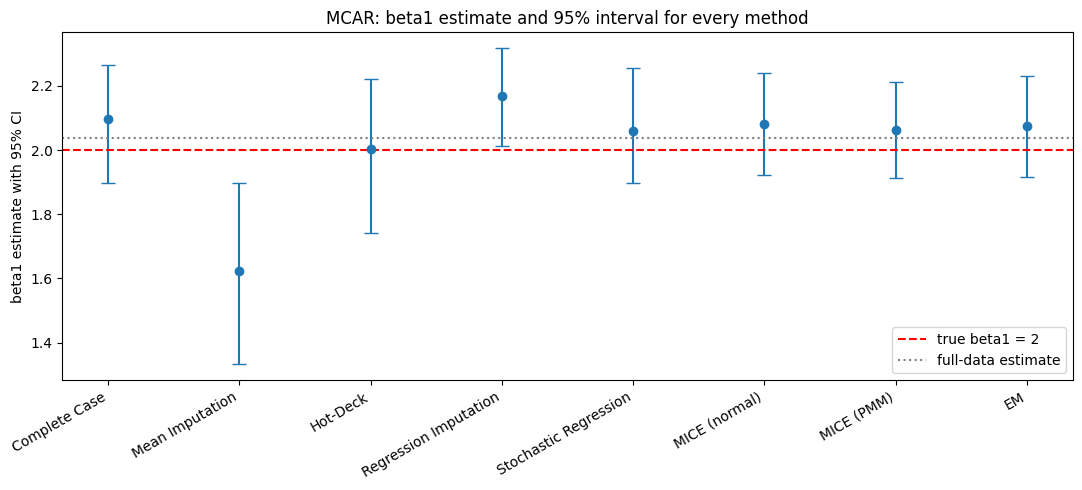

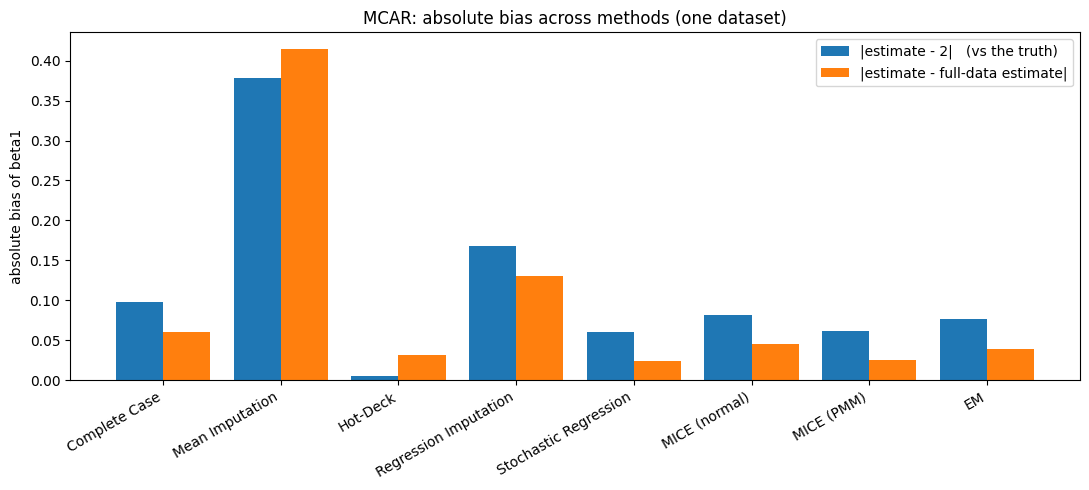

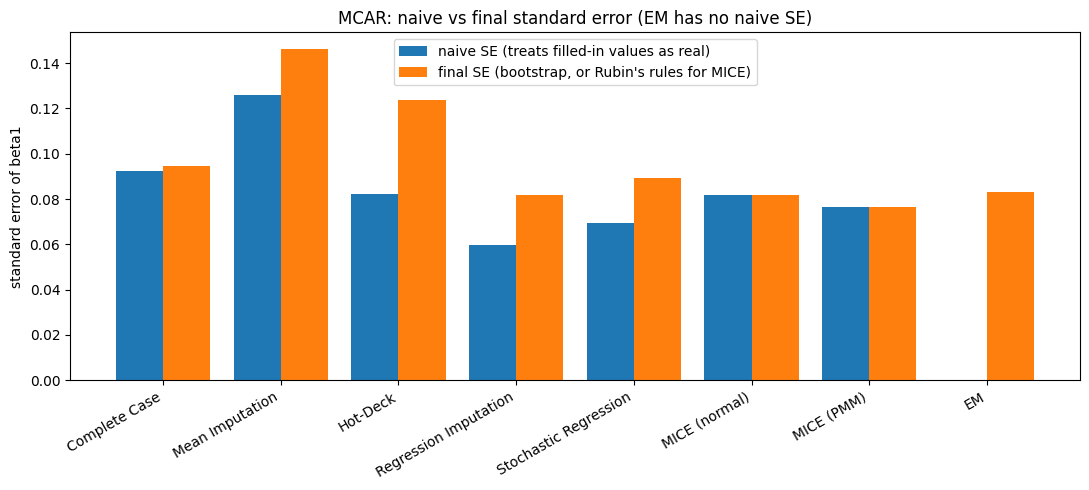

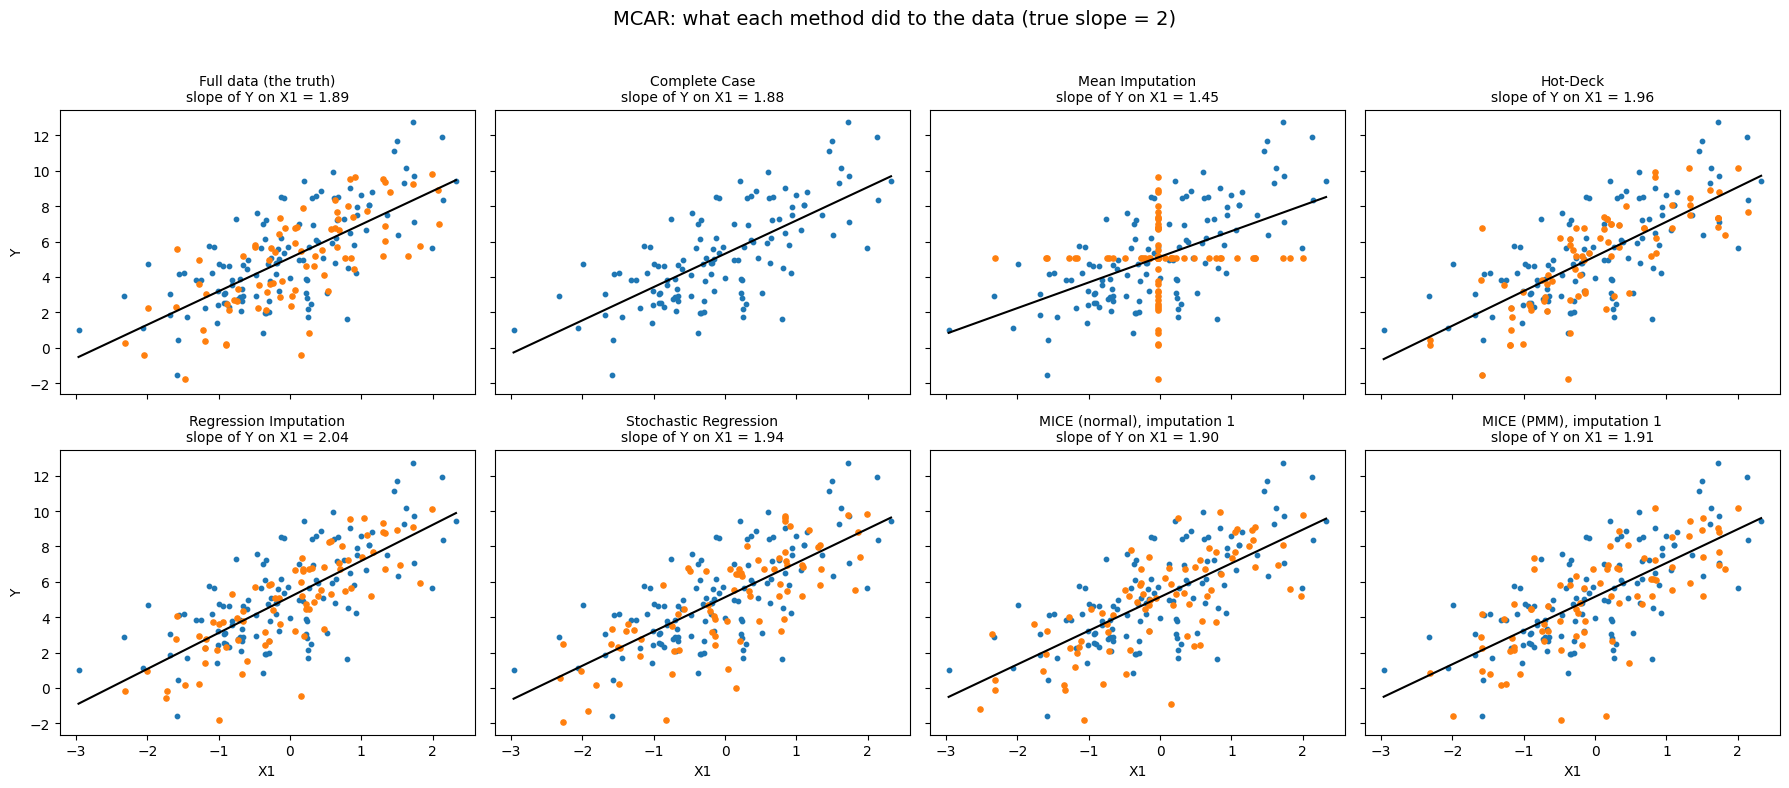

In [77]:
# ===== Step 5.10h — Part A figures: MCAR =====
plot_a_intervals("MCAR")
plot_a_bias("MCAR")
plot_a_se("MCAR")
plot_a_scatter("MCAR")

### MAR — all methods compared (one dataset)

In [78]:
# ===== Step 5.10i — Part A table: MAR =====
t = part_a[part_a["Mechanism"] == "MAR"].set_index("Method").loc[METHOD_ORDER]
t = t.assign(**{"95% CI": [f"({lo:.3f}, {hi:.3f})" for lo, hi in zip(t["CI_Low"], t["CI_High"])]})
t[["Beta1", "Naive SE", "Final SE", "95% CI", "Bias vs truth", "Diff vs full data"]].round(3)

,Beta1,Naive SE,Final SE,95% CI,Bias vs truth,Diff vs full data
Method,,,,,,
Complete Case,1.844,0.105,0.102,"(1.629, 2.053)",-0.156,-0.193
Mean Imputation,1.346,0.133,0.137,"(1.065, 1.585)",-0.654,-0.691
Hot-Deck,1.878,0.084,0.120,"(1.599, 2.063)",-0.122,-0.159
Regression Imputation,2.110,0.068,0.096,"(1.924, 2.298)",0.110,0.074
Stochastic Regression,2.085,0.079,0.099,"(1.857, 2.231)",0.085,0.048
MICE (normal),2.036,0.098,0.098,"(1.843, 2.228)",0.036,-0.001
MICE (PMM),1.943,0.099,0.099,"(1.749, 2.137)",-0.057,-0.093
EM,2.022,NaN,0.093,"(1.830, 2.197)",0.022,-0.015


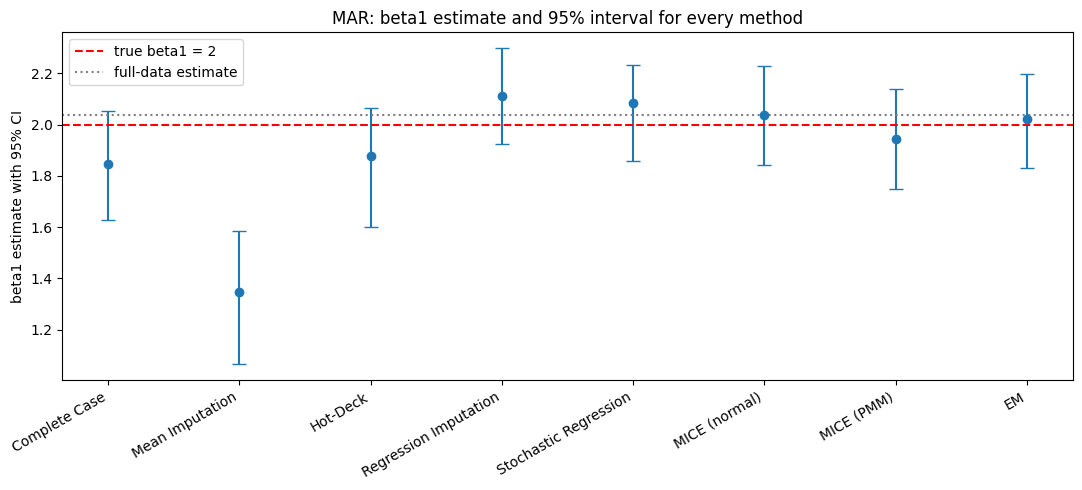

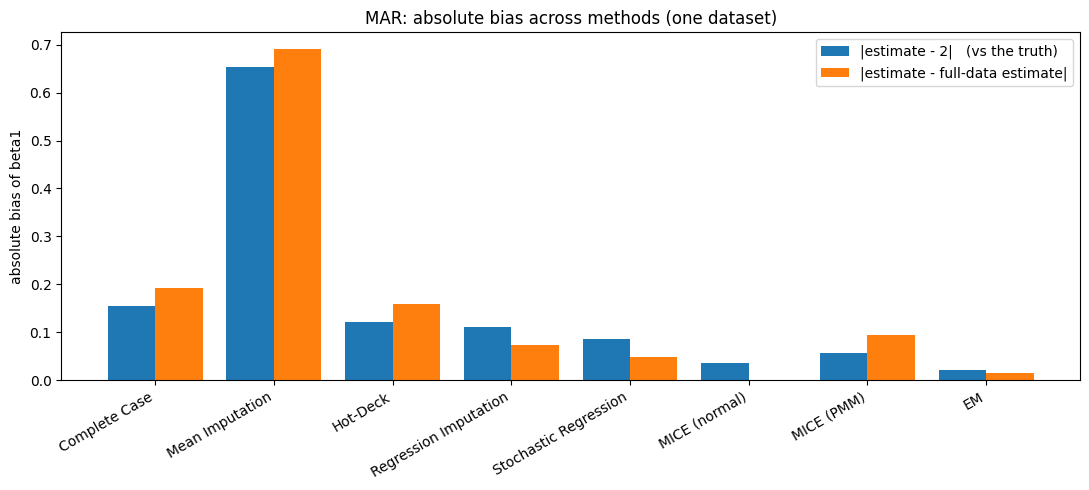

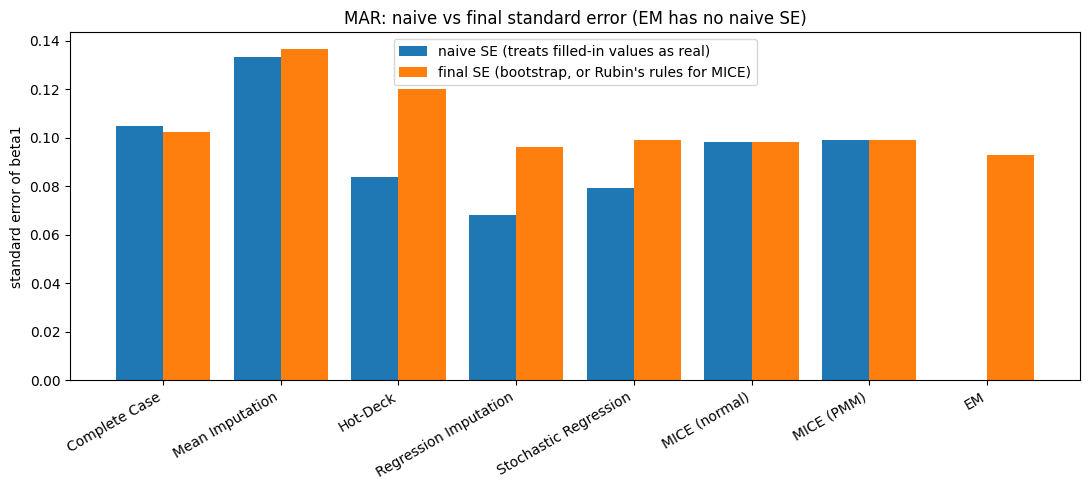

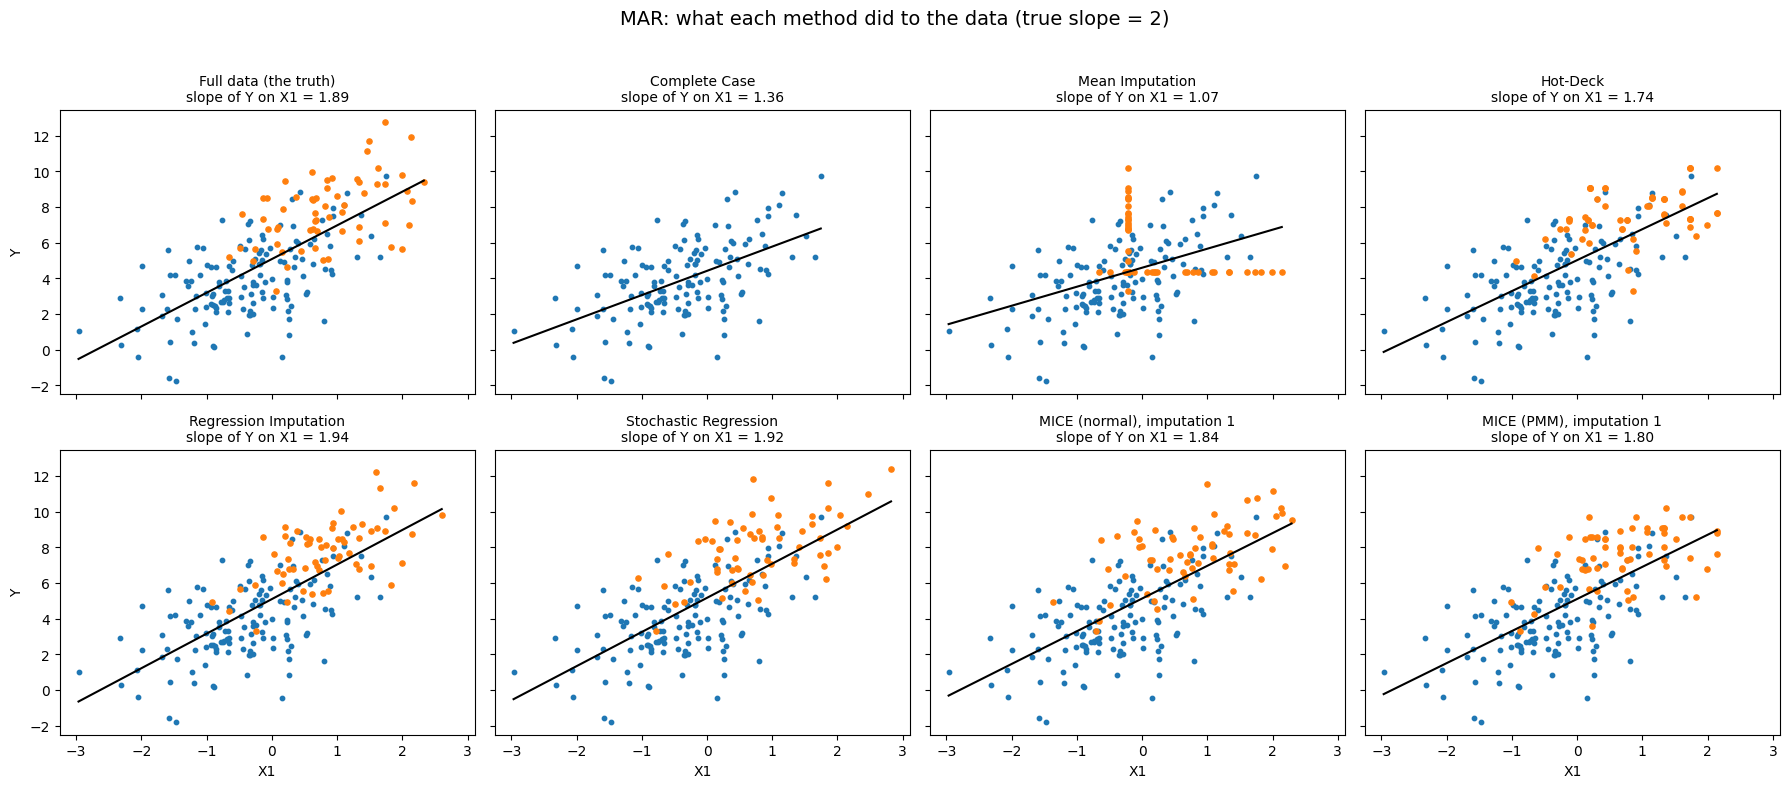

In [79]:
# ===== Step 5.10j — Part A figures: MAR =====
plot_a_intervals("MAR")
plot_a_bias("MAR")
plot_a_se("MAR")
plot_a_scatter("MAR")

### MNAR — all methods compared (one dataset)

In [80]:
# ===== Step 5.10k — Part A table: MNAR =====
t = part_a[part_a["Mechanism"] == "MNAR"].set_index("Method").loc[METHOD_ORDER]
t = t.assign(**{"95% CI": [f"({lo:.3f}, {hi:.3f})" for lo, hi in zip(t["CI_Low"], t["CI_High"])]})
t[["Beta1", "Naive SE", "Final SE", "95% CI", "Bias vs truth", "Diff vs full data"]].round(3)

,Beta1,Naive SE,Final SE,95% CI,Bias vs truth,Diff vs full data
Method,,,,,,
Complete Case,2.015,0.115,0.103,"(1.834, 2.229)",0.015,-0.022
Mean Imputation,1.263,0.151,0.167,"(0.946, 1.599)",-0.737,-0.774
Hot-Deck,1.935,0.111,0.124,"(1.692, 2.169)",-0.065,-0.102
Regression Imputation,2.212,0.071,0.091,"(2.049, 2.394)",0.212,0.175
Stochastic Regression,2.120,0.079,0.101,"(1.913, 2.311)",0.120,0.084
MICE (normal),2.107,0.082,0.082,"(1.945, 2.268)",0.107,0.070
MICE (PMM),2.047,0.111,0.111,"(1.830, 2.264)",0.047,0.010
EM,2.108,NaN,0.088,"(1.937, 2.287)",0.108,0.071


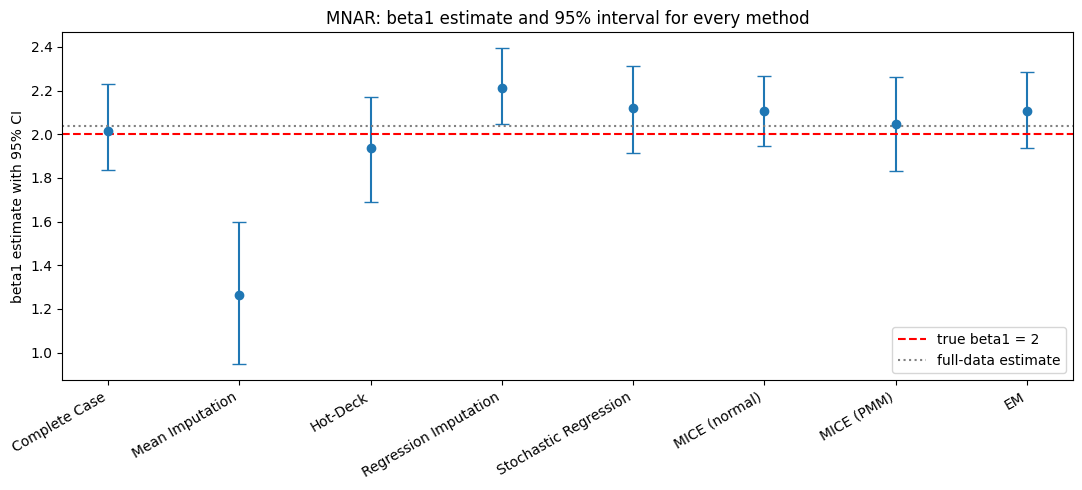

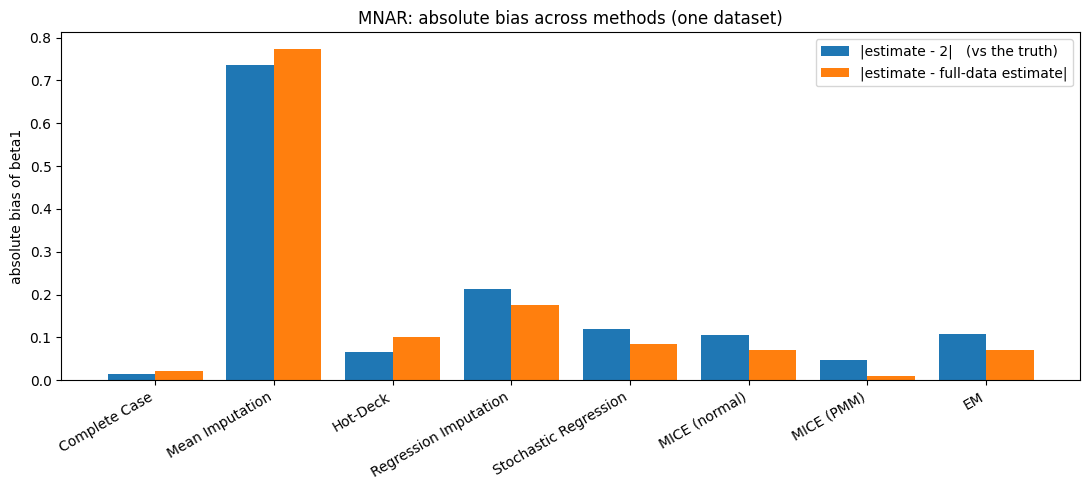

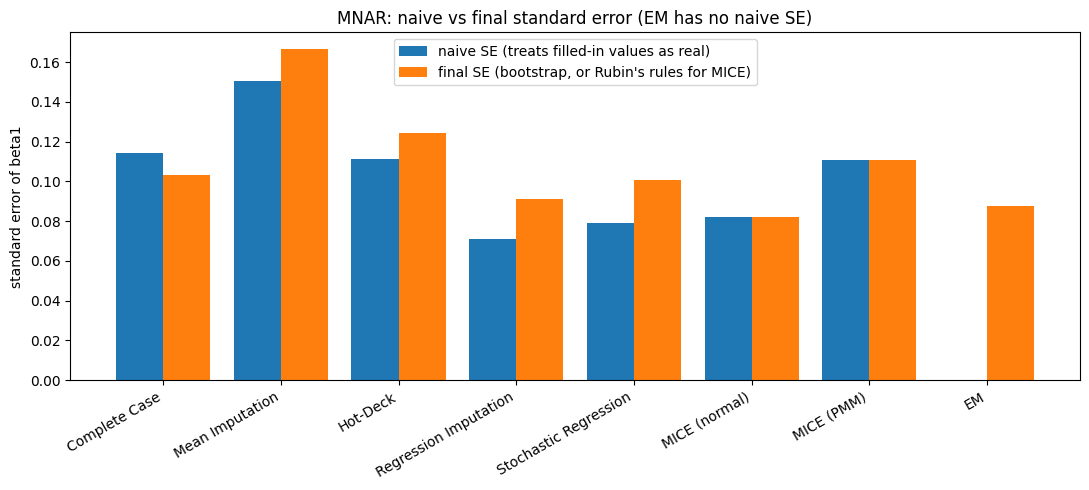

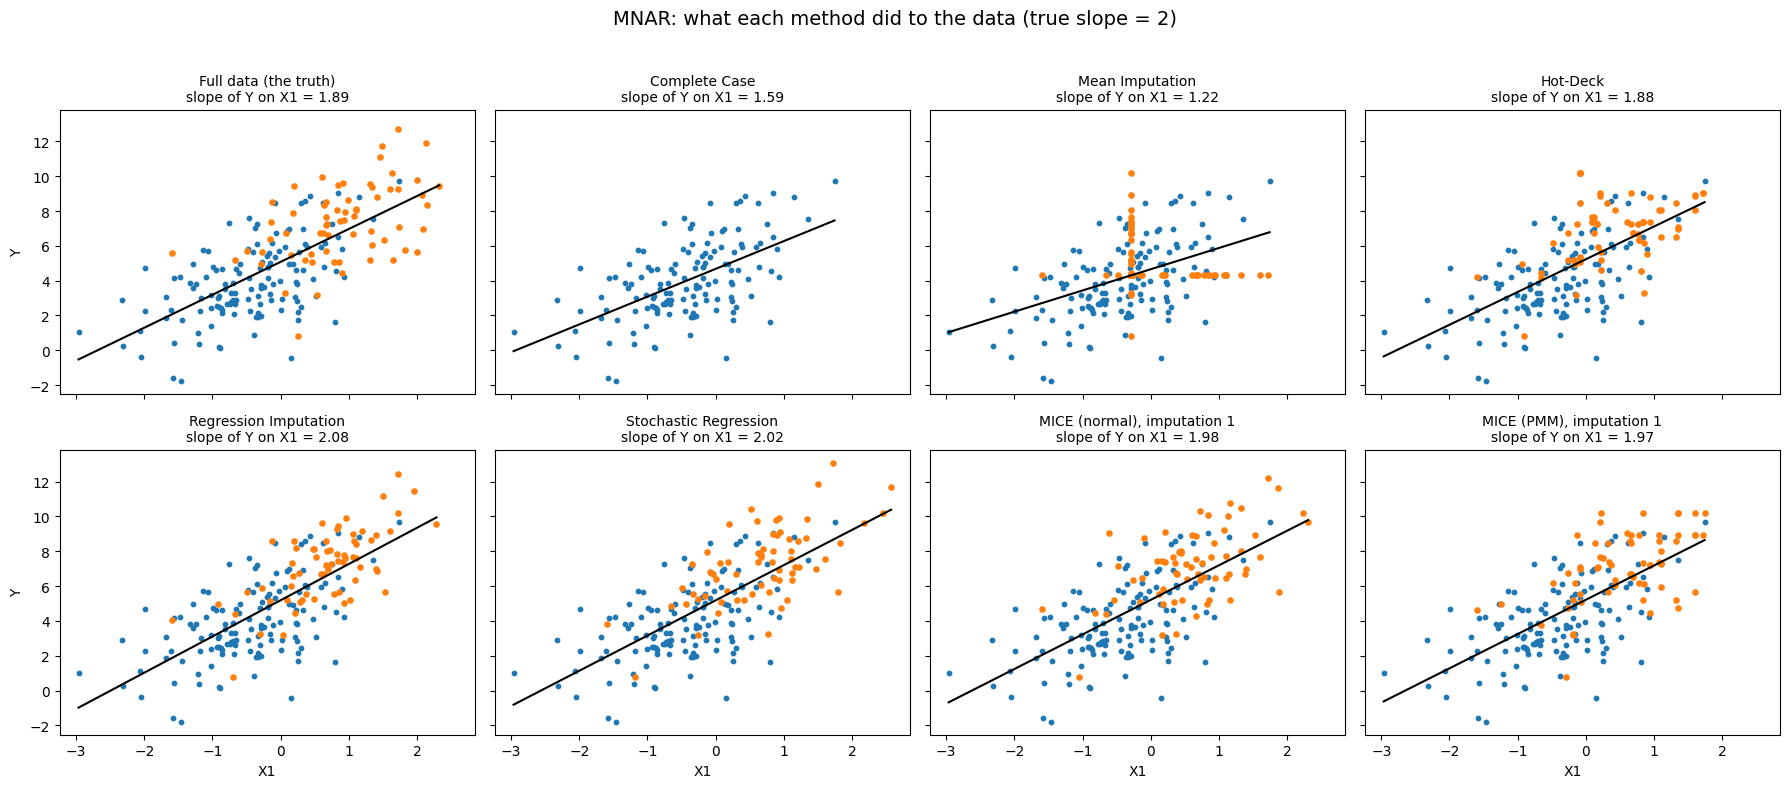

In [81]:
# ===== Step 5.10l — Part A figures: MNAR =====
plot_a_intervals("MNAR")
plot_a_bias("MNAR")
plot_a_se("MNAR")
plot_a_scatter("MNAR")

*Naive SE* = the SE you get by running the regression on the completed data and ignoring that some values were filled in (for MICE it is the Rubin's-rules SE; EM has no naive SE). *Final SE* = bootstrap SE, or Rubin's rules for MICE. Compare the two columns and the third figure: for single-imputation methods the naive SE is clearly too small.

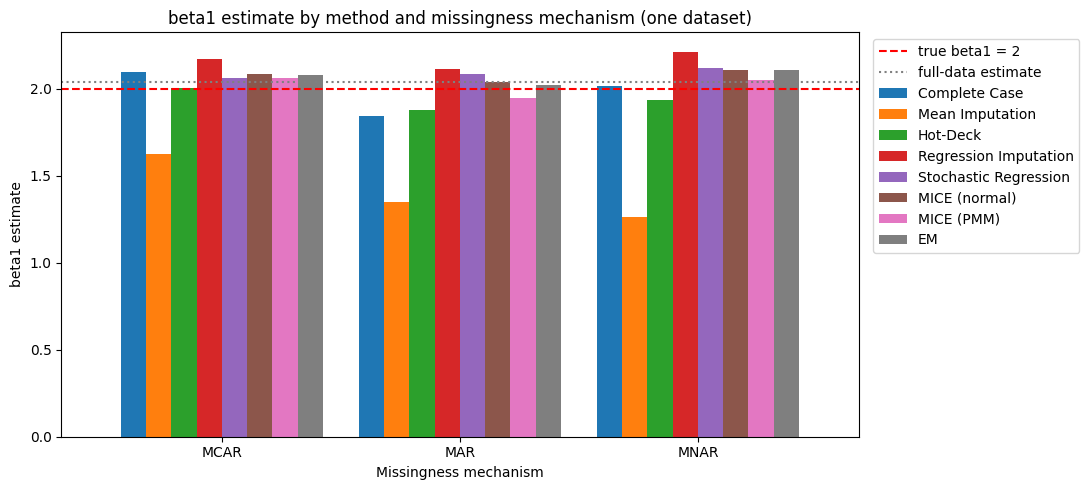

In [82]:
# ===== Step 5.10m — Overview: the three mechanisms side by side (for reference) =====
overview = part_a.pivot(index="Mechanism", columns="Method", values="Beta1").loc[MECHANISMS, METHOD_ORDER]

ax = overview.plot.bar(figsize=(11, 5), rot=0, width=0.85)
ax.axhline(2, color="red", ls="--", label="true beta1 = 2")
ax.axhline(beta_full[1], color="gray", ls=":", label="full-data estimate")
ax.set_title("beta1 estimate by method and missingness mechanism (one dataset)")
ax.set_xlabel("Missingness mechanism")
ax.set_ylabel("beta1 estimate")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**How to read Part A.** This is *one* dataset, so each number is one draw from a distribution. The full-data estimate is itself not exactly 2, which is why the *Diff vs full data* column is the fairer measure of what missing data did. Whether a method is generally biased, or generally over-confident, can only be judged by repeating the experiment — that is Part B.

# Part B — simulation study

For each of `N_REPS` repetitions a **new** complete dataset is generated, damaged under each mechanism, and analysed with every method. The same dataset is also analysed with *no* missing values, as a benchmark ("Full data").

How each repetition gets its standard error: naive OLS SE for complete case and for the single-imputation methods, Rubin's rules for MICE, and a small bootstrap (`EM_BOOT` resamples) for EM. This is deliberately what an analyst would do *without* a big bootstrap, so the study shows which methods report honest uncertainty.

| Measure | Meaning |
|---|---|
| **Bias** | average of (β̂₁ − 2) over the repetitions |
| **Bias vs full** | average of (β̂₁ − the full-data estimate from the same dataset) — separates missing-data damage from sampling noise |
| **SD** | spread of β̂₁ across repetitions = the *true* uncertainty |
| **RMSE** | overall accuracy, combining bias and spread |
| **Avg SE** | the standard error the method *reports*. If it is clearly below the SD, the method is over-confident |
| **Coverage (%)** | share of intervals β̂₁ ± 1.96·SE that contain 2. It should be about 95 |

In [83]:
# ===== Step 6a — The eight methods in one dictionary =====
# Every method is a function: (incomplete data, rng) -> (coefficients, standard errors)
METHODS = {
    "Complete Case": complete_case,
    "Mean Imputation": mean_imputation,
    "Hot-Deck": hot_deck,
    "Regression Imputation": regression_imputation,
    "Stochastic Regression": stochastic_regression,
    "MICE (normal)": mice_normal,
    "MICE (PMM)": mice_pmm,
    "EM": em,
}
print(list(METHODS))

['Complete Case', 'Mean Imputation', 'Hot-Deck', 'Regression Imputation', 'Stochastic Regression', 'MICE (normal)', 'MICE (PMM)', 'EM']


In [84]:
# ===== Step 6b — ONE repetition, to see what the simulation records =====
rng = np.random.default_rng(2024)

rep_full = make_data(rng)                              # 1. a brand-new complete dataset
rep_beta_full, rep_se_full = ols(rep_full)             #    the estimate we would get with nothing missing
rep_data = make_missing(rep_full, "MAR", rng)          # 2. damage it (here: MAR)

one_rep = []
for name, method in METHODS.items():                   # 3. apply every method
    beta, se = method(rep_data, rng)
    if se is None:                                     #    EM: no formula, so a small bootstrap
        se = bootstrap(method, rep_data, rng, EM_BOOT).std(axis=0, ddof=1)
    one_rep.append({"Method": name, "Beta1": beta[1], "SE": se[1],
                    "Interval contains 2?": abs(beta[1] - 2) <= 1.96 * se[1]})

print(f"Full-data estimate for this repetition: {rep_beta_full[1]:.3f}")
pd.DataFrame(one_rep).set_index("Method").round(3)

Full-data estimate for this repetition: 1.997


,Beta1,SE,Interval contains 2?
Method,,,
Complete Case,1.907,0.098,True
Mean Imputation,1.615,0.129,False
Hot-Deck,1.843,0.091,True
Regression Imputation,2.078,0.070,True
Stochastic Regression,1.959,0.075,True
MICE (normal),1.957,0.085,True
MICE (PMM),1.956,0.093,True
EM,1.989,0.120,True


In [85]:
# ===== Step 6c — The simulation: repeat this N_REPS times, for all three mechanisms =====
rng = np.random.default_rng(2024)
records = []

for rep in range(N_REPS):
    rep_full = make_data(rng)
    rep_beta_full, rep_se_full = ols(rep_full)
    for mech in MECHANISMS:
        rep_data = make_missing(rep_full, mech, rng)
        records.append([mech, "Full data", rep, rep_beta_full[1], rep_se_full[1], rep_beta_full[1]])
        for name, method in METHODS.items():
            beta, se = method(rep_data, rng)
            if se is None:                                   # EM: small bootstrap for the SE
                se = bootstrap(method, rep_data, rng, EM_BOOT).std(axis=0, ddof=1)
            records.append([mech, name, rep, beta[1], se[1], rep_beta_full[1]])
    if (rep + 1) % 50 == 0:
        print(f"{rep + 1} / {N_REPS} repetitions done")

50 / 300 repetitions done


100 / 300 repetitions done


150 / 300 repetitions done


200 / 300 repetitions done


250 / 300 repetitions done


300 / 300 repetitions done


In [86]:
# ===== Step 6d — Put all the records into a table =====
sim = pd.DataFrame(records, columns=["Mechanism", "Method", "Rep", "Beta1", "SE", "Beta1_full"])
print("Rows:", len(sim), "  (= repetitions x mechanisms x 9 methods incl. the full-data benchmark)")
sim.head(10).round(3)

Rows: 8100   (= repetitions x mechanisms x 9 methods incl. the full-data benchmark)


,Mechanism,Method,Rep,Beta1,SE,Beta1_full
0,MCAR,Full data,0,1.997,0.078,1.997
1,MCAR,Complete Case,0,1.983,0.096,1.997
2,MCAR,Mean Imputation,0,1.673,0.124,1.997
3,MCAR,Hot-Deck,0,1.877,0.082,1.997
4,MCAR,Regression Imputation,0,2.058,0.071,1.997
5,MCAR,Stochastic Regression,0,2.018,0.080,1.997
6,MCAR,MICE (normal),0,1.965,0.094,1.997
7,MCAR,MICE (PMM),0,1.974,0.094,1.997
8,MCAR,EM,0,1.978,0.086,1.997
9,MAR,Full data,0,1.997,0.078,1.997


In [87]:
# ===== Step 6e — For every row: the error, and did the 95% interval contain the truth? =====
sim["Error"] = sim["Beta1"] - 2
sim["Covered"] = sim["Error"].abs() <= 1.96 * sim["SE"]
sim[["Mechanism", "Method", "Beta1", "SE", "Error", "Covered"]].head(10).round(3)

,Mechanism,Method,Beta1,SE,Error,Covered
0,MCAR,Full data,1.997,0.078,-0.003,True
1,MCAR,Complete Case,1.983,0.096,-0.017,True
2,MCAR,Mean Imputation,1.673,0.124,-0.327,False
3,MCAR,Hot-Deck,1.877,0.082,-0.123,True
4,MCAR,Regression Imputation,2.058,0.071,0.058,True
5,MCAR,Stochastic Regression,2.018,0.080,0.018,True
6,MCAR,MICE (normal),1.965,0.094,-0.035,True
7,MCAR,MICE (PMM),1.974,0.094,-0.026,True
8,MCAR,EM,1.978,0.086,-0.022,True
9,MAR,Full data,1.997,0.078,-0.003,True


In [88]:
# ===== Step 6f — Summarise: one row per mechanism and method =====
summary = sim.groupby(["Mechanism", "Method"], sort=False).agg(
    Bias=("Error", "mean"),
    SD=("Beta1", "std"),
    RMSE=("Error", lambda e: np.sqrt((e ** 2).mean())),
    Avg_SE=("SE", "mean"),
    Coverage=("Covered", "mean"),
)
summary["Bias vs full"] = (sim["Beta1"] - sim["Beta1_full"]).groupby([sim["Mechanism"], sim["Method"]], sort=False).mean()
summary["Coverage (%)"] = 100 * summary.pop("Coverage")
summary = summary[["Bias", "Bias vs full", "SD", "RMSE", "Avg_SE", "Coverage (%)"]]

ROUNDING = {"Bias": 3, "Bias vs full": 3, "SD": 3, "RMSE": 3, "Avg_SE": 3, "Coverage (%)": 1}
print("Summary table built:", summary.shape)

Summary table built: (27, 6)


### Tools for comparing the methods within one mechanism

Each mechanism gets the same four things: a **ranked table**, and three figures —

1. **Distribution of the estimates** — one box per method: where do the 300 estimates of β₁ fall relative to the truth (red line)? This shows bias (box centred away from 2) and variability (box height) at a glance.
2. **Dashboard** — bias (with Monte Carlo error bars), RMSE, coverage of the 95% interval (shaded band = Monte Carlo error around 95%), and *reported SE ÷ true spread* (below 1 = over-confident).
3. **Individual intervals** — the first 30 confidence intervals of each method; **green** = contains the truth, **red** = misses it. The coverage percentage in the title is over all repetitions.

In [89]:
# ===== Step 6g — Ranked table =====
order = ["Full data"] + list(METHODS)


def ranked_table(mech):
    """The methods under one mechanism, best (lowest RMSE) first."""
    t = summary.loc[mech].drop("Full data").sort_values("RMSE")
    t.insert(0, "Rank by RMSE", range(1, len(t) + 1))
    return t


def show_benchmark():
    b = summary.loc[("MCAR", "Full data")]
    print(f"Benchmark with NO missing data: SD = {b['SD']:.3f}, RMSE = {b['RMSE']:.3f}, coverage = {b['Coverage (%)']:.1f}%  "
          f"(no method can beat this)")

In [90]:
# ===== Step 6h — Figure 1: distribution of the estimates =====
def plot_b_distribution(mech):
    t = sim[sim["Mechanism"] == mech]
    groups = [t.loc[t["Method"] == name, "Beta1"].to_numpy() for name in order]
    plt.figure(figsize=(12, 5.5))
    plt.boxplot(groups, showfliers=False)
    plt.axhline(2, color="red", ls="--", label="true beta1 = 2")
    plt.xticks(range(1, len(order) + 1), order, rotation=30, ha="right")
    plt.ylabel("estimate of beta1")
    plt.title(f"{mech}: distribution of the beta1 estimate over {N_REPS} repetitions")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [91]:
# ===== Step 6i — Figure 2: dashboard (bias, RMSE, coverage, honesty of the reported SE) =====
def plot_b_dashboard(mech):
    t = summary.loc[mech].loc[order]
    y = np.arange(len(t))
    mc_bias = 1.96 * t["SD"] / np.sqrt(N_REPS)                         # Monte Carlo error of an average bias
    mc_cov = 100 * 1.96 * np.sqrt(0.95 * 0.05 / N_REPS)                # Monte Carlo error of a coverage near 95%

    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

    axes[0, 0].barh(y, t["Bias"], xerr=mc_bias, capsize=3)
    axes[0, 0].axvline(0, color="black")
    axes[0, 0].set_title("Bias of beta1  (error bars = Monte Carlo error)")

    axes[0, 1].barh(y, t["RMSE"], color="tab:purple")
    axes[0, 1].set_title("RMSE  (lower = more accurate)")

    axes[1, 0].barh(y, t["Coverage (%)"], color="tab:green")
    axes[1, 0].axvline(95, color="black", ls="--")
    axes[1, 0].axvspan(95 - mc_cov, 95 + mc_cov, color="gray", alpha=0.25)
    axes[1, 0].set_xlim(0, 100)
    axes[1, 0].set_title("Coverage of the 95% interval  (grey band = Monte Carlo error around 95%)")

    axes[1, 1].barh(y, t["Avg_SE"] / t["SD"], color="tab:red")
    axes[1, 1].axvline(1, color="black", ls="--")
    axes[1, 1].set_title("Reported SE / true spread  (below 1 = over-confident)")

    axes[0, 0].set_yticks(y)
    axes[0, 0].set_yticklabels(t.index)
    axes[0, 0].invert_yaxis()
    fig.suptitle(f"{mech}: how do the methods compare?", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [92]:
# ===== Step 6j — Figure 3: the first 30 confidence intervals of every method =====
def plot_b_intervals(mech, n_show=30):
    fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True)
    for ax, name in zip(axes.ravel(), order):
        t = sim[(sim["Mechanism"] == mech) & (sim["Method"] == name) & (sim["Rep"] < n_show)]
        low = (t["Beta1"] - 1.96 * t["SE"]).to_numpy()
        high = (t["Beta1"] + 1.96 * t["SE"]).to_numpy()
        covers = (low <= 2) & (2 <= high)
        ax.hlines(t["Rep"], low, high, colors=np.where(covers, "tab:green", "tab:red"))
        ax.plot(t["Beta1"], t["Rep"], "k.", markersize=3)
        ax.axvline(2, color="black", ls="--")
        ax.set_title(f"{name}   (coverage {summary.loc[(mech, name), 'Coverage (%)']:.0f}%)", fontsize=10)
        ax.set_yticks([])
    fig.suptitle(f"{mech}: {n_show} confidence intervals per method  (green = contains 2, red = misses)", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

### MCAR — all methods compared (simulation)

In [93]:
# ===== Step 6k — Part B ranked table: MCAR =====
show_benchmark()
ranked_table("MCAR").round(ROUNDING)

Benchmark with NO missing data: SD = 0.070, RMSE = 0.070, coverage = 95.0%  (no method can beat this)


,Rank by RMSE,Bias,Bias vs full,SD,RMSE,Avg_SE,Coverage (%)
Method,,,,,,,
MICE (normal),1,-0.005,-0.006,0.080,0.080,0.083,95.7
EM,2,-0.001,-0.001,0.080,0.080,0.082,94.3
MICE (PMM),3,-0.011,-0.011,0.082,0.083,0.083,95.7
Complete Case,4,0.001,0.000,0.085,0.085,0.089,96.0
Stochastic Regression,5,-0.003,-0.003,0.092,0.091,0.071,85.7
Regression Imputation,6,0.081,0.080,0.081,0.114,0.062,68.0
Hot-Deck,7,-0.094,-0.095,0.098,0.136,0.084,74.3
Mean Imputation,8,-0.397,-0.398,0.133,0.419,0.125,12.3


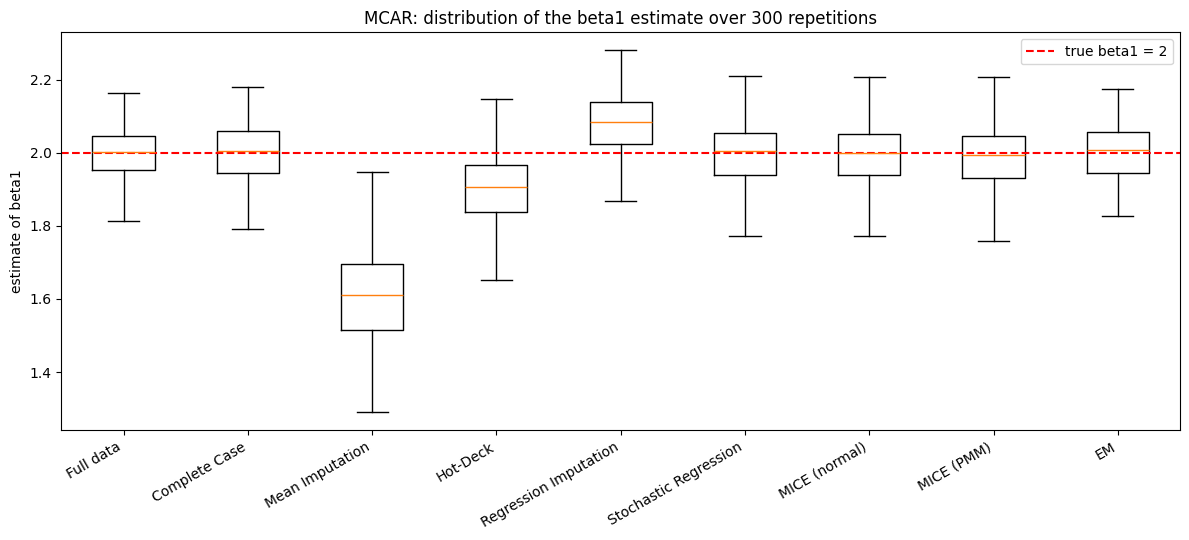

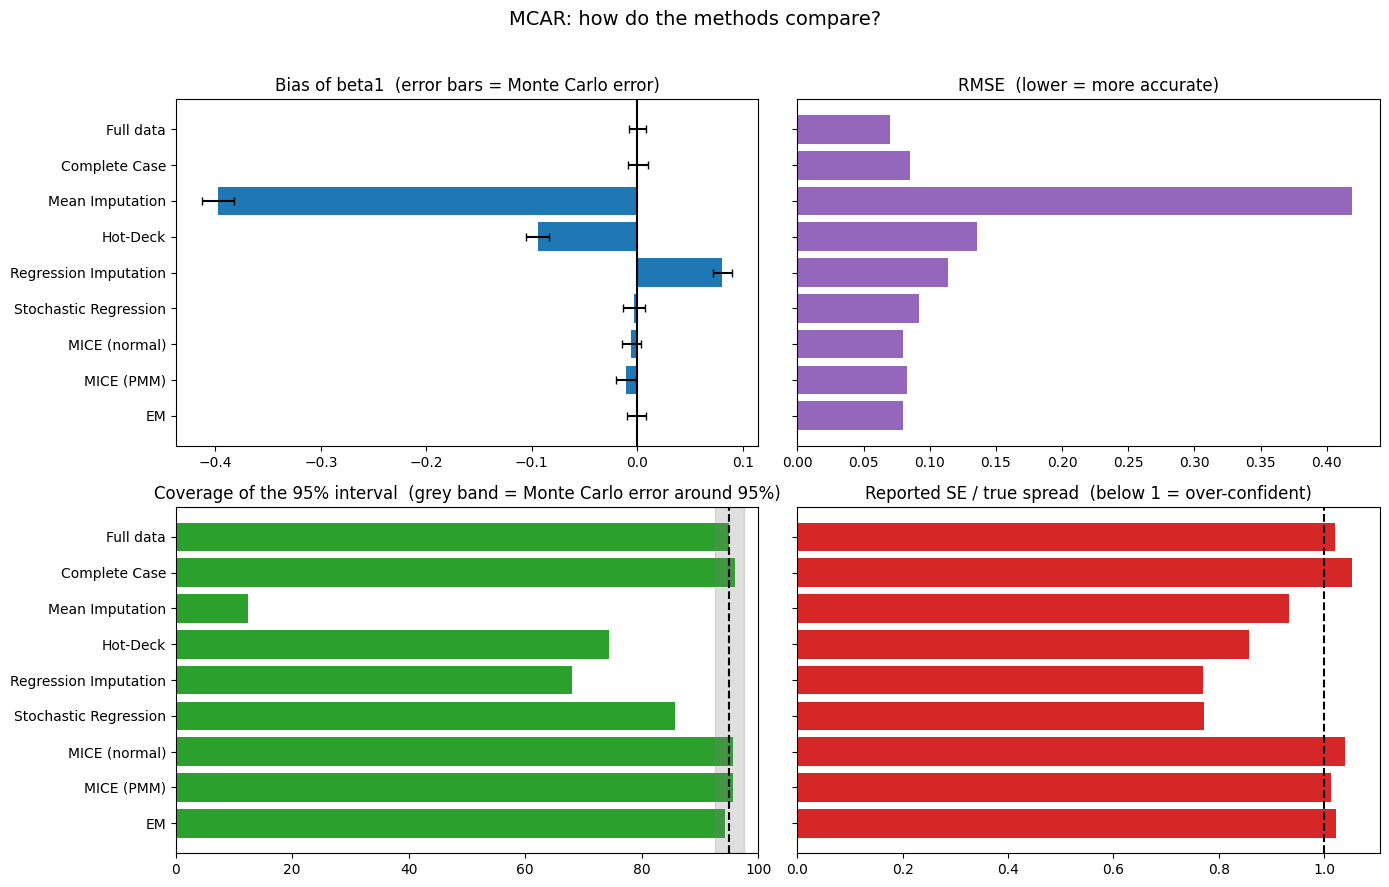

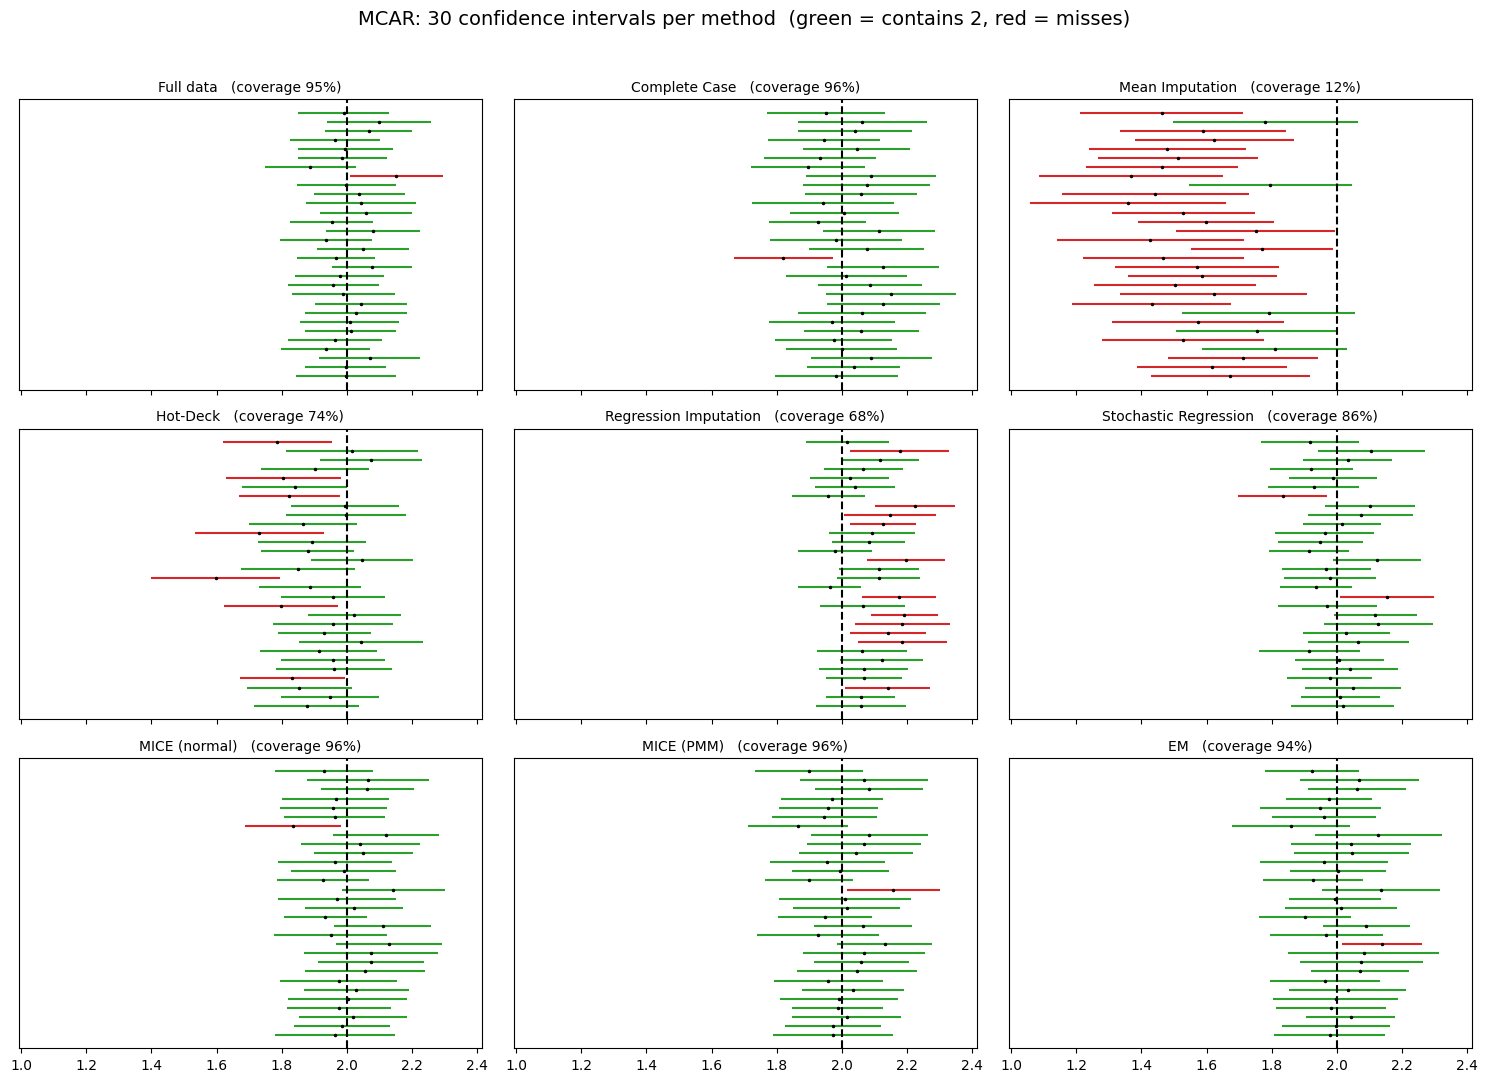

In [94]:
# ===== Step 6l — Part B figures: MCAR =====
plot_b_distribution("MCAR")
plot_b_dashboard("MCAR")
plot_b_intervals("MCAR")

### MAR — all methods compared (simulation)

In [95]:
# ===== Step 6m — Part B ranked table: MAR =====
show_benchmark()
ranked_table("MAR").round(ROUNDING)

Benchmark with NO missing data: SD = 0.070, RMSE = 0.070, coverage = 95.0%  (no method can beat this)


,Rank by RMSE,Bias,Bias vs full,SD,RMSE,Avg_SE,Coverage (%)
Method,,,,,,,
EM,1,0.002,0.001,0.085,0.085,0.086,95.3
MICE (normal),2,-0.001,-0.002,0.086,0.086,0.087,95.3
Stochastic Regression,3,0.006,0.005,0.092,0.092,0.072,86.3
MICE (PMM),4,-0.052,-0.052,0.097,0.110,0.091,87.7
Regression Imputation,5,0.084,0.083,0.087,0.121,0.065,71.3
Complete Case,6,-0.100,-0.101,0.093,0.136,0.092,79.7
Hot-Deck,7,-0.147,-0.147,0.124,0.192,0.089,57.7
Mean Imputation,8,-0.471,-0.472,0.130,0.489,0.128,5.3


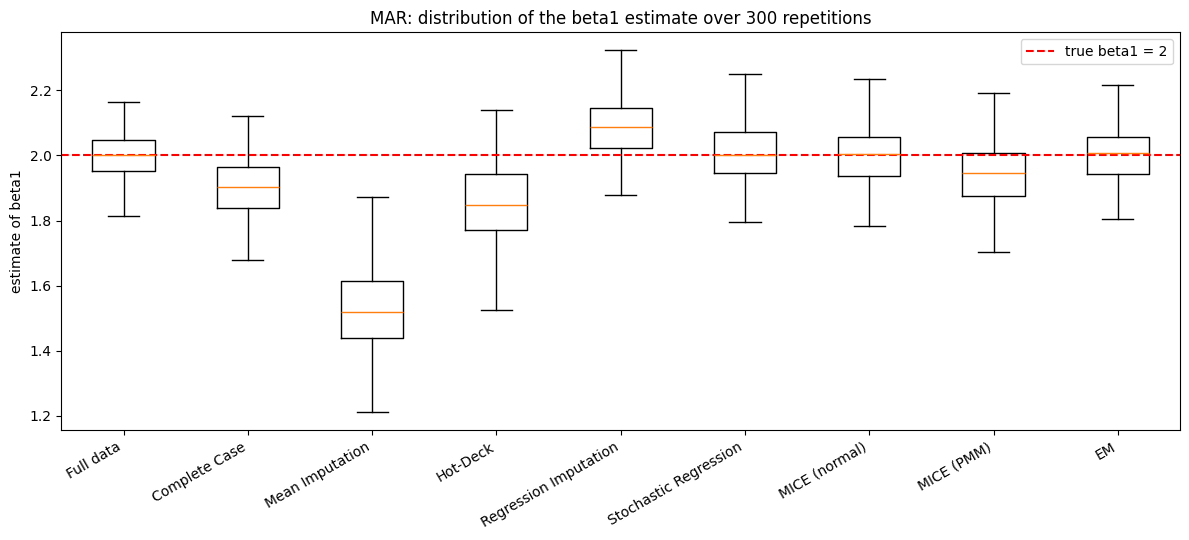

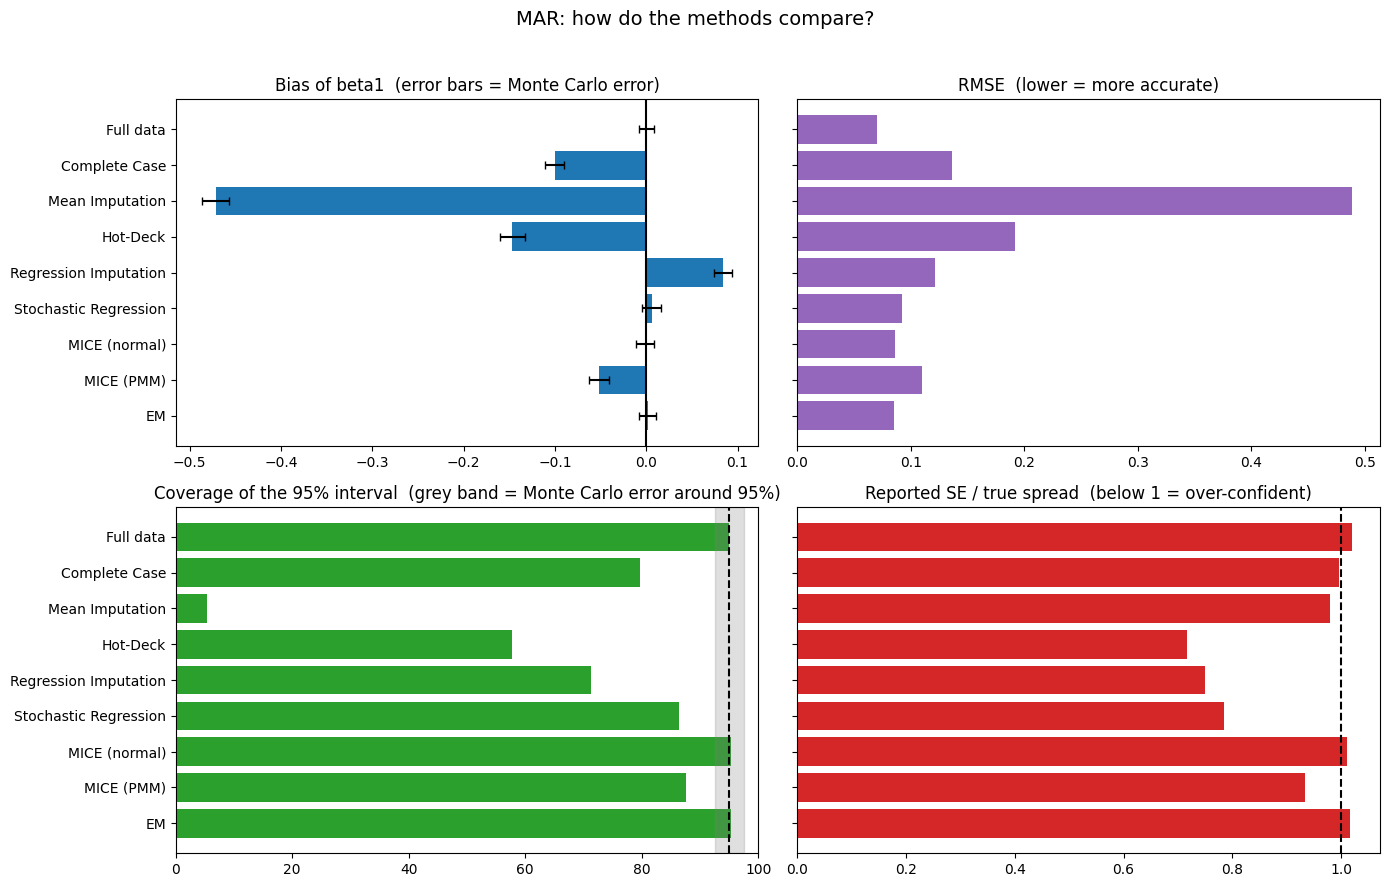

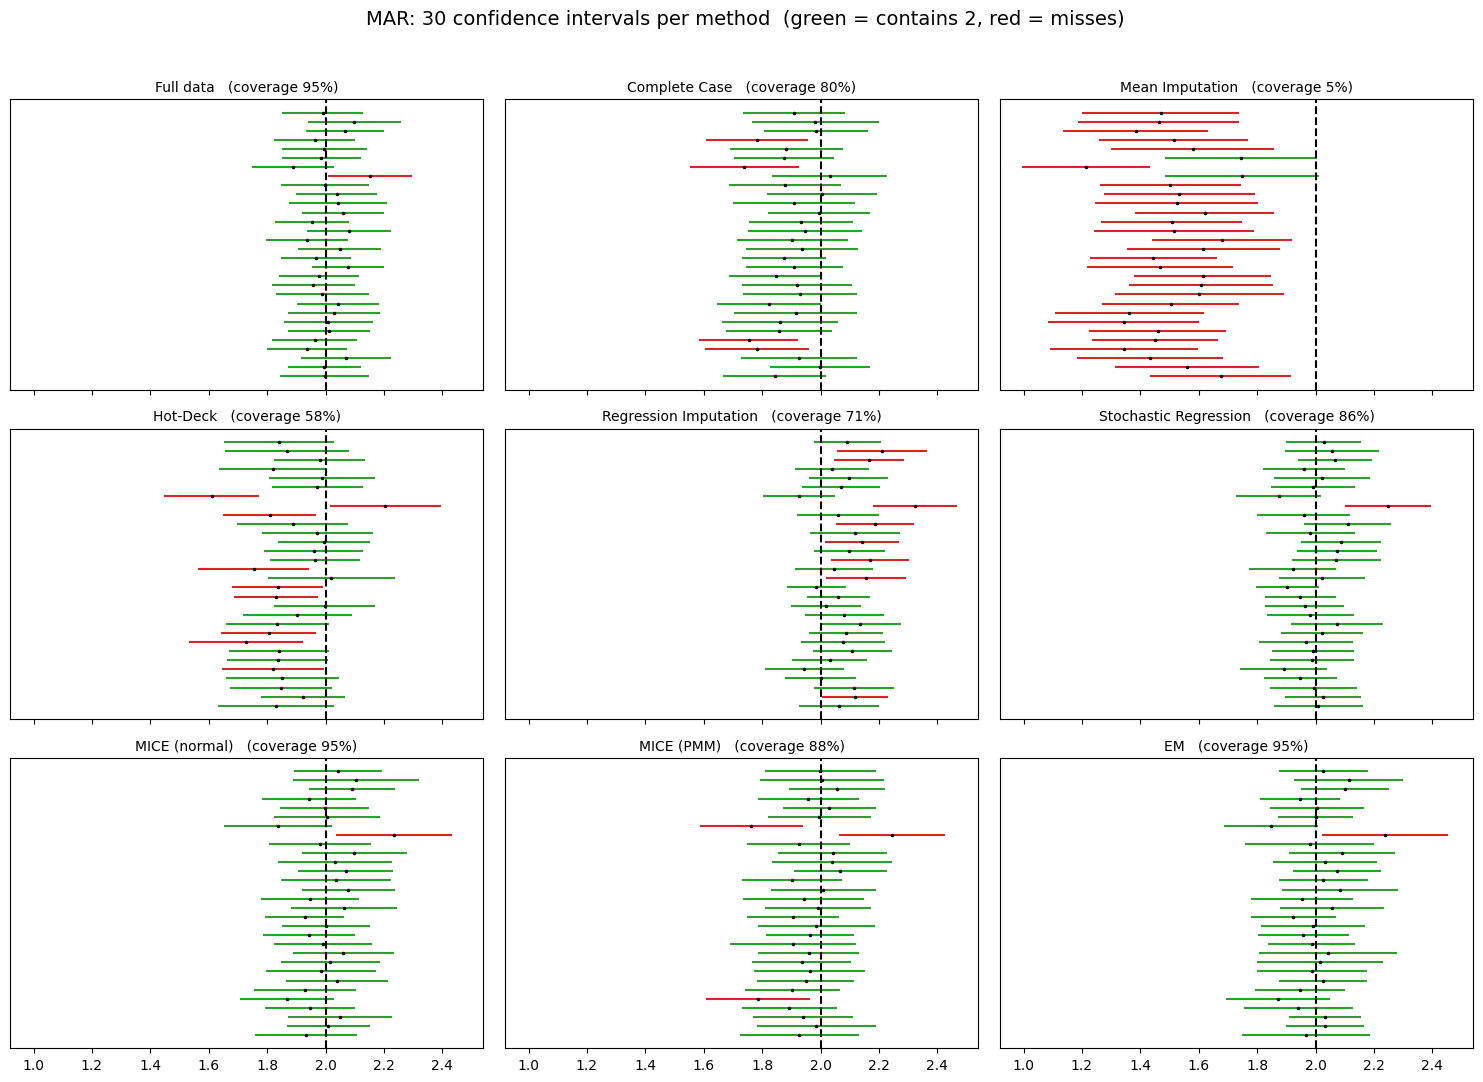

In [96]:
# ===== Step 6n — Part B figures: MAR =====
plot_b_distribution("MAR")
plot_b_dashboard("MAR")
plot_b_intervals("MAR")

### MNAR — all methods compared (simulation)

In [97]:
# ===== Step 6o — Part B ranked table: MNAR =====
show_benchmark()
ranked_table("MNAR").round(ROUNDING)

Benchmark with NO missing data: SD = 0.070, RMSE = 0.070, coverage = 95.0%  (no method can beat this)


,Rank by RMSE,Bias,Bias vs full,SD,RMSE,Avg_SE,Coverage (%)
Method,,,,,,,
MICE (PMM),1,0.016,0.016,0.112,0.113,0.098,91.3
MICE (normal),2,0.063,0.063,0.096,0.115,0.094,89.7
EM,3,0.066,0.066,0.095,0.116,0.092,88.7
Complete Case,4,-0.061,-0.062,0.106,0.123,0.102,90.7
Stochastic Regression,5,0.069,0.069,0.103,0.124,0.078,81.3
Hot-Deck,6,-0.046,-0.047,0.128,0.136,0.096,84.7
Regression Imputation,7,0.154,0.154,0.099,0.183,0.070,43.3
Mean Imputation,8,-0.547,-0.547,0.156,0.569,0.147,5.7


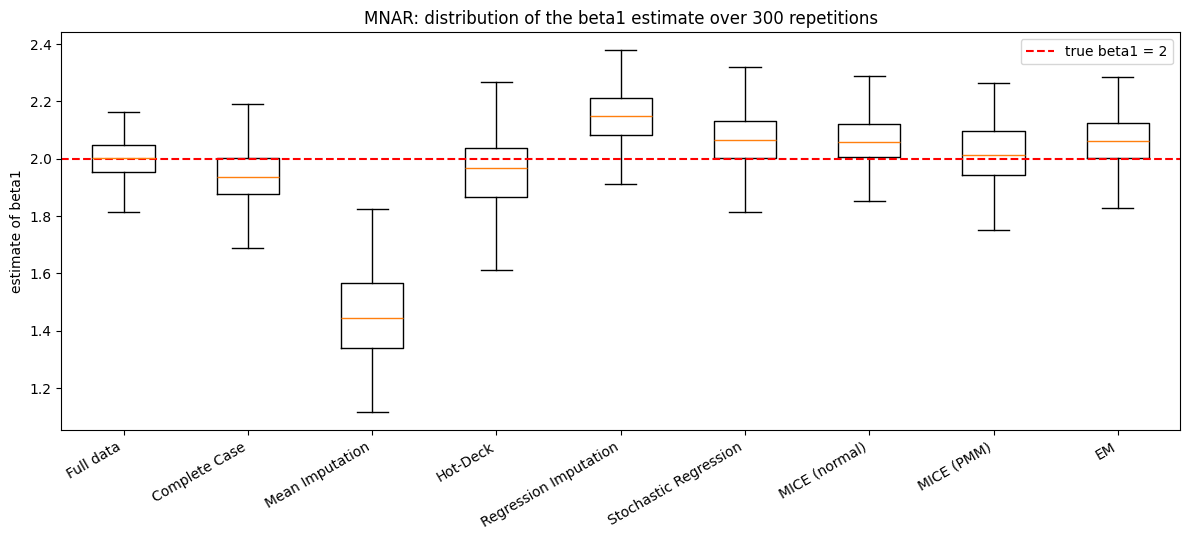

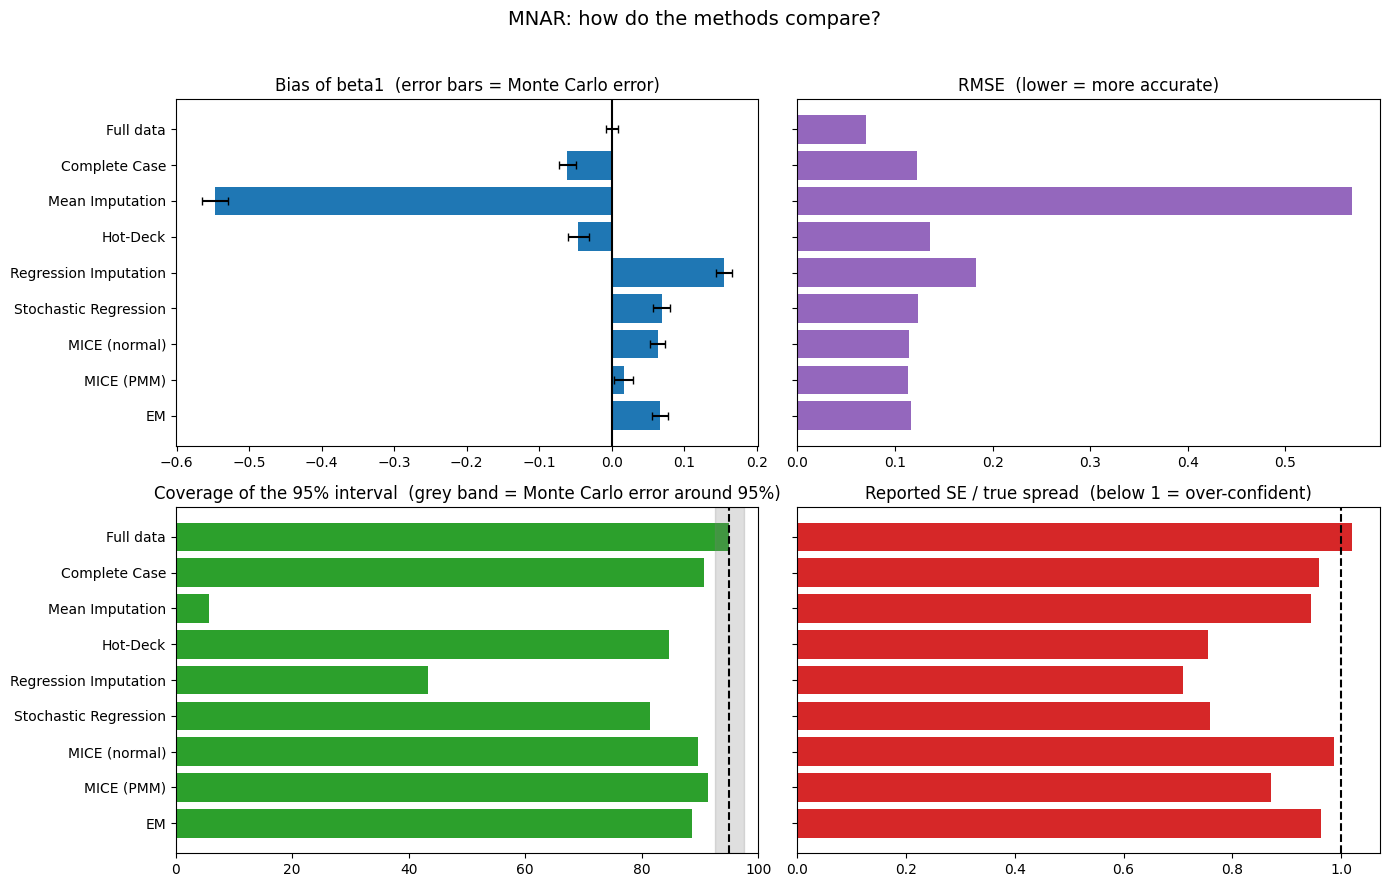

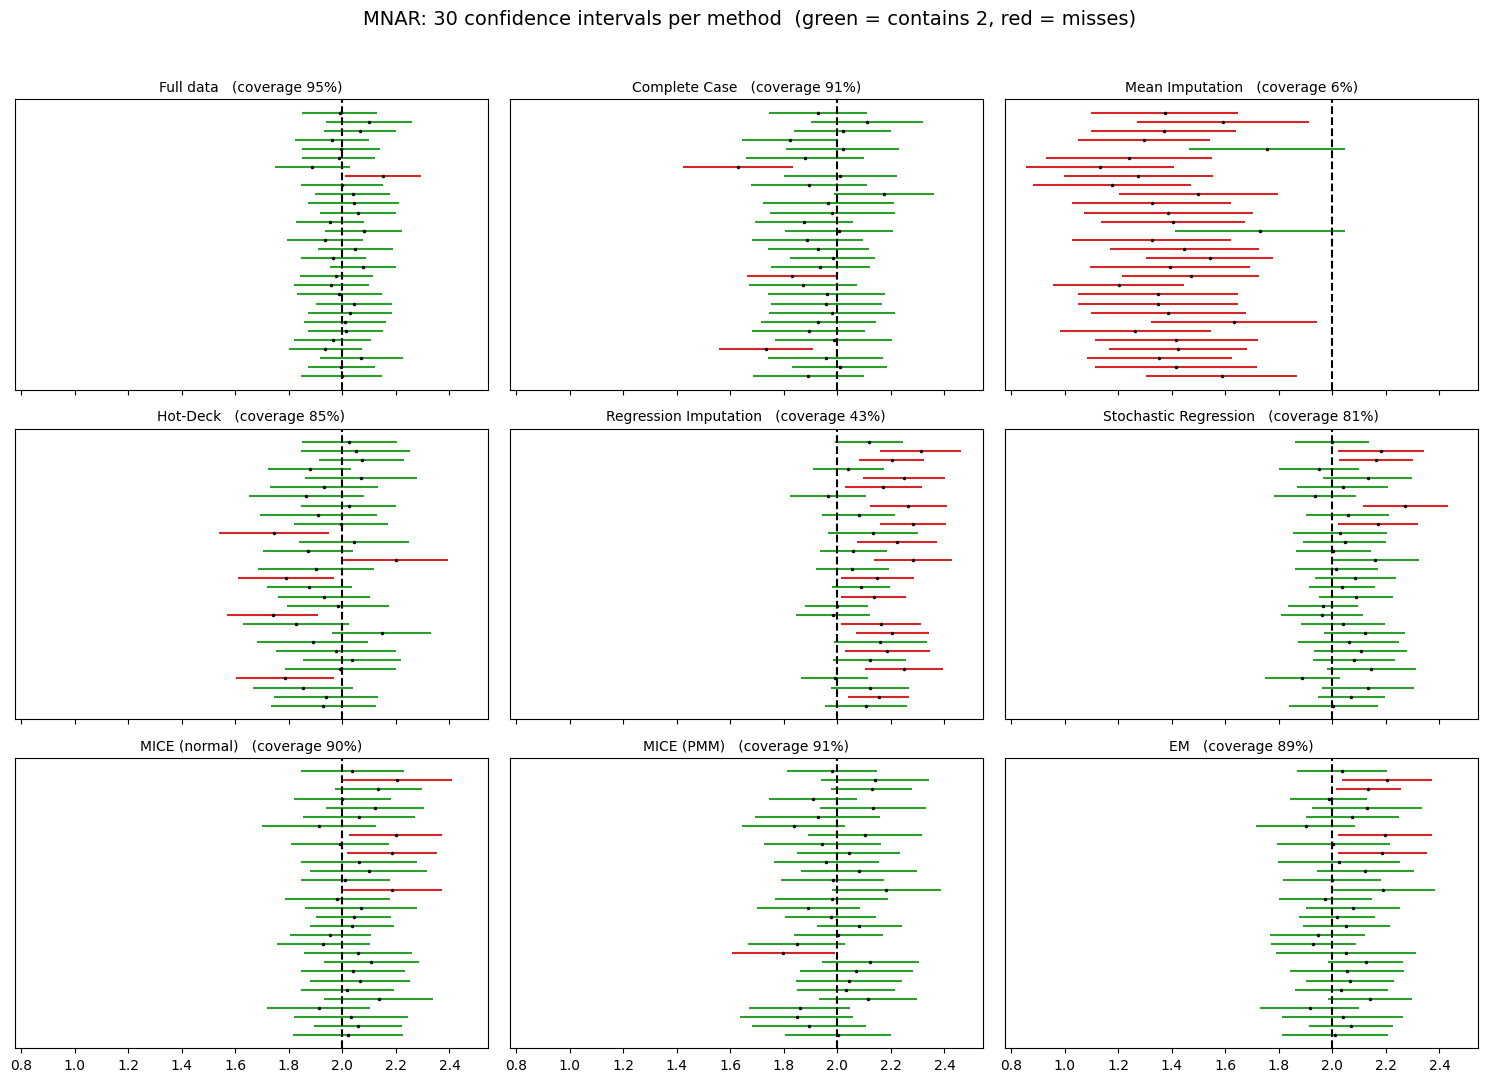

In [98]:
# ===== Step 6p — Part B figures: MNAR =====
plot_b_distribution("MNAR")
plot_b_dashboard("MNAR")
plot_b_intervals("MNAR")

### Overview — the three mechanisms side by side (for reference only)

The comparisons that matter are the ones *within* each mechanism above. These three charts just put all of them on one page.

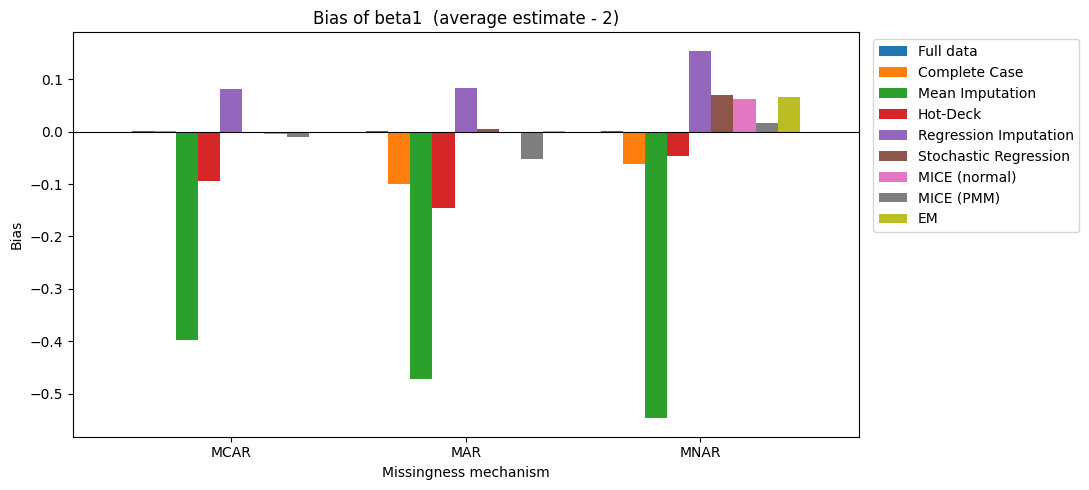

In [99]:
# ===== Step 6q — Overview: bias =====
bias = summary["Bias"].unstack("Method")[order].loc[MECHANISMS]

ax = bias.plot.bar(figsize=(11, 5), rot=0, width=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Bias of beta1  (average estimate - 2)")
ax.set_xlabel("Missingness mechanism")
ax.set_ylabel("Bias")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

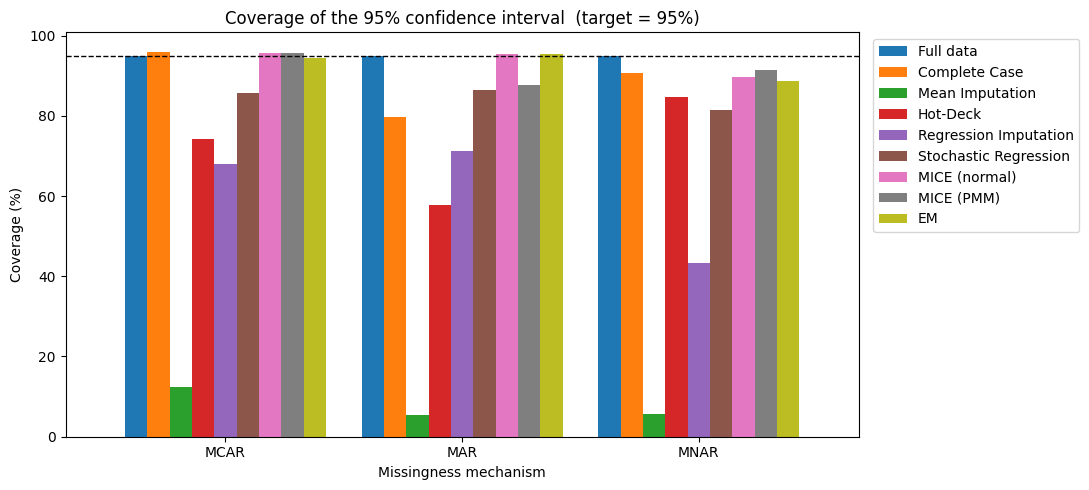

In [100]:
# ===== Step 6r — Overview: coverage of the 95% interval =====
coverage = summary["Coverage (%)"].unstack("Method")[order].loc[MECHANISMS]

ax = coverage.plot.bar(figsize=(11, 5), rot=0, width=0.85)
ax.axhline(95, color="black", ls="--", lw=1)
ax.set_title("Coverage of the 95% confidence interval  (target = 95%)")
ax.set_xlabel("Missingness mechanism")
ax.set_ylabel("Coverage (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

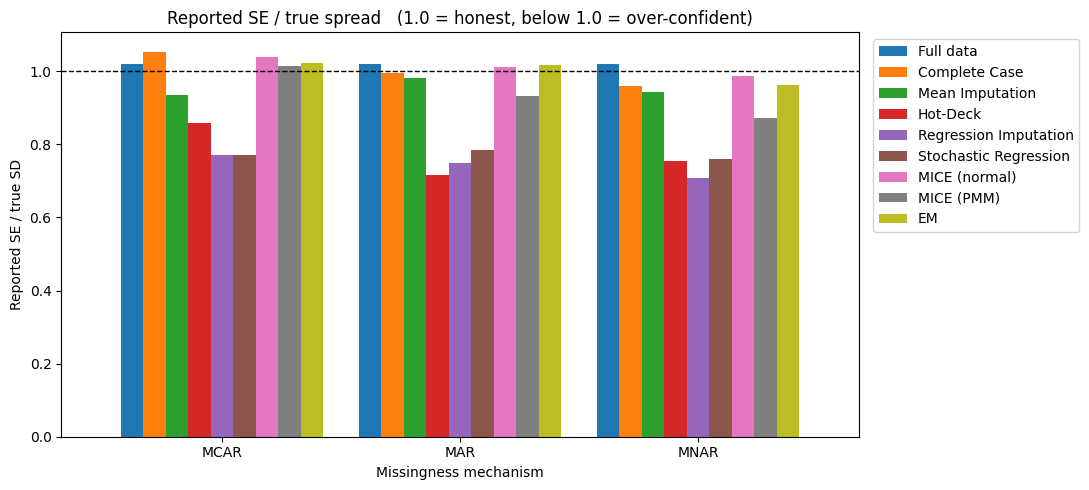

In [101]:
# ===== Step 6s — Overview: does the method report honest uncertainty? =====
honesty = (summary["Avg_SE"] / summary["SD"]).unstack("Method")[order].loc[MECHANISMS]

ax = honesty.plot.bar(figsize=(11, 5), rot=0, width=0.85)
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_title("Reported SE / true spread   (1.0 = honest, below 1.0 = over-confident)")
ax.set_xlabel("Missingness mechanism")
ax.set_ylabel("Reported SE / true SD")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# Master tables and interpretation

First, **all results in consolidated tables** (also saved as CSV files), and a table of the **best method under each mechanism**. Then a block of text **generated from those results**, so its numbers always match the tables, followed by the explanation of what the patterns mean — again one mechanism at a time.

In [102]:
# ===== Step 7a — Settings used =====
print(f"Settings: N = {N} observations, true beta1 = 2, {N_REPS} simulation repetitions, "
      f"{M_IMPUTATIONS} imputations (MICE), {B_BOOT} bootstrap samples (Part A), {EM_BOOT} (EM inside Part B).")

Settings: N = 200 observations, true beta1 = 2, 300 simulation repetitions, 10 imputations (MICE), 500 bootstrap samples (Part A), 40 (EM inside Part B).


In [103]:
# ===== Step 7b — Part A master table: one dataset, all methods, all mechanisms =====
part_a_cols = ["Beta1", "Final SE", "Bias vs truth", "Diff vs full data"]
master_a = pd.concat(
    {mech: part_a[part_a["Mechanism"] == mech].set_index("Method")[part_a_cols] for mech in MECHANISMS},
    axis=1,
).loc[METHOD_ORDER]

print(f"Full-data estimate of beta1 for this dataset: {beta_full[1]:.3f}  (true value 2)")
master_a.round(3)

Full-data estimate of beta1 for this dataset: 2.037  (true value 2)


MCAR                                             MAR  \
                       Beta1 Final SE Bias vs truth Diff vs full data  Beta1   
Method                                                                         
Complete Case          2.098    0.094         0.098             0.061  1.844   
Mean Imputation        1.622    0.146        -0.378            -0.415  1.346   
Hot-Deck               2.005    0.124         0.005            -0.032  1.878   
Regression Imputation  2.168    0.082         0.168             0.131  2.110   
Stochastic Regression  2.060    0.089         0.060             0.023  2.085   
MICE (normal)          2.082    0.082         0.082             0.045  2.036   
MICE (PMM)             2.062    0.077         0.062             0.025  1.943   
EM                     2.076    0.083         0.076             0.040  2.022   

                                                                 MNAR  \
                      Final SE Bias vs truth Diff vs full data  Beta1   
Method                                                                  
Complete Case            0.102        -0.156            -0.193  2.015   
Mean Imputation          0.137        -0.654            -0.691  1.263   
Hot-Deck                 0.120        -0.122            -0.159  1.935   
Regression Imputation    0.096         0.110             0.074  2.212   
Stochastic Regression    0.099         0.085             0.048  2.120   
MICE (normal)            0.098         0.036            -0.001  2.107   
MICE (PMM)               0.099        -0.057            -0.093  2.047   
EM                       0.093         0.022            -0.015  2.108   

                                                                
                      Final SE Bias vs truth Diff vs full data  
Method                                                          
Complete Case            0.103         0.015            -0.022  
Mean Imputation          0.167        -0.737            -0.774  
Hot-Deck                 0.124        -0.065            -0.102  
Regression Imputation    0.091         0.212             0.175  
Stochastic Regression    0.101         0.120             0.084  
MICE (normal)            0.082         0.107             0.070  
MICE (PMM)               0.111         0.047             0.010  
EM                       0.088         0.108             0.071

In [104]:
# ===== Step 7c — Part B master table: the full simulation summary =====
with pd.option_context("display.max_rows", None):
    display(summary.round(ROUNDING))

Bias  Bias vs full     SD   RMSE  Avg_SE  \
Mechanism Method                                                             
MCAR      Full data              0.000         0.000  0.070  0.070   0.072   
          Complete Case          0.001         0.000  0.085  0.085   0.089   
          Mean Imputation       -0.397        -0.398  0.133  0.419   0.125   
          Hot-Deck              -0.094        -0.095  0.098  0.136   0.084   
          Regression Imputation  0.081         0.080  0.081  0.114   0.062   
          Stochastic Regression -0.003        -0.003  0.092  0.091   0.071   
          MICE (normal)         -0.005        -0.006  0.080  0.080   0.083   
          MICE (PMM)            -0.011        -0.011  0.082  0.083   0.083   
          EM                    -0.001        -0.001  0.080  0.080   0.082   
MAR       Full data              0.000         0.000  0.070  0.070   0.072   
          Complete Case         -0.100        -0.101  0.093  0.136   0.092   
          Mean Imputation       -0.471        -0.472  0.130  0.489   0.128   
          Hot-Deck              -0.147        -0.147  0.124  0.192   0.089   
          Regression Imputation  0.084         0.083  0.087  0.121   0.065   
          Stochastic Regression  0.006         0.005  0.092  0.092   0.072   
          MICE (normal)         -0.001        -0.002  0.086  0.086   0.087   
          MICE (PMM)            -0.052        -0.052  0.097  0.110   0.091   
          EM                     0.002         0.001  0.085  0.085   0.086   
MNAR      Full data              0.000         0.000  0.070  0.070   0.072   
          Complete Case         -0.061        -0.062  0.106  0.123   0.102   
          Mean Imputation       -0.547        -0.547  0.156  0.569   0.147   
          Hot-Deck              -0.046        -0.047  0.128  0.136   0.096   
          Regression Imputation  0.154         0.154  0.099  0.183   0.070   
          Stochastic Regression  0.069         0.069  0.103  0.124   0.078   
          MICE (normal)          0.063         0.063  0.096  0.115   0.094   
          MICE (PMM)             0.016         0.016  0.112  0.113   0.098   
          EM                     0.066         0.066  0.095  0.116   0.092   

                                 Coverage (%)  
Mechanism Method                               
MCAR      Full data                      95.0  
          Complete Case                  96.0  
          Mean Imputation                12.3  
          Hot-Deck                       74.3  
          Regression Imputation          68.0  
          Stochastic Regression          85.7  
          MICE (normal)                  95.7  
          MICE (PMM)                     95.7  
          EM                             94.3  
MAR       Full data                      95.0  
          Complete Case                  79.7  
          Mean Imputation                 5.3  
          Hot-Deck                       57.7  
          Regression Imputation          71.3  
          Stochastic Regression          86.3  
          MICE (normal)                  95.3  
          MICE (PMM)                     87.7  
          EM                             95.3  
MNAR      Full data                      95.0  
          Complete Case                  90.7  
          Mean Imputation                 5.7  
          Hot-Deck                       84.7  
          Regression Imputation          43.3  
          Stochastic Regression          81.3  
          MICE (normal)                  89.7  
          MICE (PMM)                     91.3  
          EM                             88.7

In [105]:
# ===== Step 7d — Scoreboard: bias, RMSE and coverage side by side =====
rows_order = ["Full data"] + list(METHODS)
scoreboard = pd.concat(
    {metric: summary[metric].unstack("Mechanism")[MECHANISMS].loc[rows_order].round(1 if "%" in metric else 3)
     for metric in ["Bias", "RMSE", "Coverage (%)"]},
    axis=1,
)
scoreboard

Bias                 RMSE               Coverage (%)  \
Mechanism               MCAR    MAR   MNAR   MCAR    MAR   MNAR         MCAR   
Method                                                                         
Full data              0.000  0.000  0.000  0.070  0.070  0.070         95.0   
Complete Case          0.001 -0.100 -0.061  0.085  0.136  0.123         96.0   
Mean Imputation       -0.397 -0.471 -0.547  0.419  0.489  0.569         12.3   
Hot-Deck              -0.094 -0.147 -0.046  0.136  0.192  0.136         74.3   
Regression Imputation  0.081  0.084  0.154  0.114  0.121  0.183         68.0   
Stochastic Regression -0.003  0.006  0.069  0.091  0.092  0.124         85.7   
MICE (normal)         -0.005 -0.001  0.063  0.080  0.086  0.115         95.7   
MICE (PMM)            -0.011 -0.052  0.016  0.083  0.110  0.113         95.7   
EM                    -0.001  0.002  0.066  0.080  0.085  0.116         94.3   

                                   
Mechanism               MAR  MNAR  
Method                             
Full data              95.0  95.0  
Complete Case          79.7  90.7  
Mean Imputation         5.3   5.7  
Hot-Deck               57.7  84.7  
Regression Imputation  71.3  43.3  
Stochastic Regression  86.3  81.3  
MICE (normal)          95.3  89.7  
MICE (PMM)             87.7  91.3  
EM                     95.3  88.7

In [106]:
# ===== Step 7e — Which method is best under each mechanism? =====
winners = []
for mech in MECHANISMS:
    t = summary.loc[mech].drop("Full data")
    honest = t[t["Coverage (%)"] >= 90]                       # methods whose intervals can be trusted
    winners.append({
        "Mechanism": mech,
        "Lowest RMSE": t["RMSE"].idxmin(),
        "Smallest |bias|": t["Bias"].abs().idxmin(),
        "Coverage closest to 95%": (t["Coverage (%)"] - 95).abs().idxmin(),
        "Lowest RMSE among methods with coverage of at least 90%": honest["RMSE"].idxmin() if len(honest) else "none",
    })
pd.DataFrame(winners).set_index("Mechanism")

,Lowest RMSE,Smallest |bias|,Coverage closest to 95%,Lowest RMSE among methods with coverage of at least 90%
Mechanism,,,,
MCAR,MICE (normal),Complete Case,EM,MICE (normal)
MAR,EM,MICE (normal),MICE (normal),EM
MNAR,MICE (PMM),MICE (PMM),MICE (PMM),MICE (PMM)


In [107]:
# ===== Step 7f — Save everything to CSV files =====
part_a.to_csv("part_a_results.csv", index=False)
summary.to_csv("simulation_summary.csv")
sim.drop(columns=["Covered"]).to_csv("simulation_all_repetitions.csv", index=False)
print("Saved in the notebook's folder: part_a_results.csv, simulation_summary.csv, simulation_all_repetitions.csv")

Saved in the notebook's folder: part_a_results.csv, simulation_summary.csv, simulation_all_repetitions.csv


In [108]:
# ===== Step 7g — Findings generated from the results =====
bench = summary.loc[("MCAR", "Full data"), "Coverage (%)"]
mc_error = 100 * np.sqrt(0.95 * 0.05 / N_REPS)
lines = [f"*Sanity check:* the full-data benchmark covers the truth in **{bench:.1f}%** of intervals "
         f"(should be about 95; Monte Carlo error is roughly +/-{mc_error:.1f} points with {N_REPS} repetitions)."]

for mech in MECHANISMS:
    t = summary.loc[mech].drop("Full data")
    best_bias, worst_bias = t["Bias"].abs().idxmin(), t["Bias"].abs().idxmax()
    best_rmse = t["RMSE"].idxmin()
    good = t.index[t["Coverage (%)"] >= 90].tolist()
    poor = t.index[t["Coverage (%)"] < 80].tolist()
    overconfident = t.index[t["Avg_SE"] < 0.85 * t["SD"]].tolist()
    lines.append(
        f"**{mech}.** Smallest bias: {best_bias} ({t.loc[best_bias, 'Bias']:+.3f}); "
        f"largest bias: {worst_bias} ({t.loc[worst_bias, 'Bias']:+.3f}). "
        f"Lowest RMSE: {best_rmse} ({t.loc[best_rmse, 'RMSE']:.3f}); complete case: {t.loc['Complete Case', 'RMSE']:.3f}. "
        f"Coverage of at least 90%: {', '.join(good) or 'none'}. Coverage below 80%: {', '.join(poor) or 'none'}. "
        f"Reported SE more than 15% below the true spread (over-confident): {', '.join(overconfident) or 'none'}."
    )
display(Markdown("\n\n".join(lines)))

*Sanity check:* the full-data benchmark covers the truth in **95.0%** of intervals (should be about 95; Monte Carlo error is roughly +/-1.3 points with 300 repetitions).

**MCAR.** Smallest bias: Complete Case (+0.001); largest bias: Mean Imputation (-0.397). Lowest RMSE: MICE (normal) (0.080); complete case: 0.085. Coverage of at least 90%: Complete Case, MICE (normal), MICE (PMM), EM. Coverage below 80%: Mean Imputation, Hot-Deck, Regression Imputation. Reported SE more than 15% below the true spread (over-confident): Regression Imputation, Stochastic Regression.

**MAR.** Smallest bias: MICE (normal) (-0.001); largest bias: Mean Imputation (-0.471). Lowest RMSE: EM (0.085); complete case: 0.136. Coverage of at least 90%: MICE (normal), EM. Coverage below 80%: Complete Case, Mean Imputation, Hot-Deck, Regression Imputation. Reported SE more than 15% below the true spread (over-confident): Hot-Deck, Regression Imputation, Stochastic Regression.

**MNAR.** Smallest bias: MICE (PMM) (+0.016); largest bias: Mean Imputation (-0.547). Lowest RMSE: MICE (PMM) (0.113); complete case: 0.123. Coverage of at least 90%: Complete Case, MICE (PMM). Coverage below 80%: Mean Imputation, Regression Imputation. Reported SE more than 15% below the true spread (over-confident): Hot-Deck, Regression Imputation, Stochastic Regression.

### What the results show — one mechanism at a time

*(These statements describe the default run — seed 2024, 300 repetitions. Differences between neighbouring methods that are smaller than the Monte Carlo error — such as two RMSE values a few thousandths apart — should not be over-read.)*

#### MCAR — the gaps are pure luck
* **Complete case is fine here.** It is unbiased and its intervals are honest; its only cost is precision, because it throws away a large share of the rows. **MICE and EM recover part of that precision** and are among the most accurate methods, but the gap to complete case is small.
* **MICE (normal), MICE (PMM) and EM** have coverage close to 95%.
* **The single-imputation methods fail even though the data are MCAR.** Mean imputation is strongly biased towards zero (filling with a constant removes variation) and its intervals almost never contain the truth. Regression imputation is biased upward (the filled values lie exactly on the line, which overstates the relationships), and hot-deck downward. Stochastic regression is almost unbiased, but its reported standard error is clearly smaller than the true spread, so its intervals under-cover.
* **Take-away:** under MCAR bias is not the problem for complete case; the choice among the good methods is about precision. Avoid mean imputation and single imputation.

#### MAR — the gaps depend on an observed variable (Z)
* **Complete case is no longer safe.** It is biased downward and its coverage drops sharply, because the rows with a missing Y are not a random subset — they differ in Z, which is tied to Y.
* **EM and MICE (normal) fix this.** They use Z, are essentially unbiased, cover about 95% and have a much lower RMSE than complete case. *Variables that explain why data are missing belong in the imputation model, even if they are not in the analysis model.*
* **MICE (PMM)** shows a small downward bias and lower coverage than MICE (normal). The data here are exactly linear and normal, so the parametric model is correct and PMM's usual advantage (robustness to odd distributions) is not needed. A likely reason for its weakness is that donors can only come from observed values, and rows with extreme predicted values — exactly the ones MAR targets — have few similar donors.
* **Single imputation again under-covers:** stochastic regression is unbiased but over-confident; hot-deck and regression imputation are biased and over-confident; mean imputation is by far the worst.
* **Take-away:** MAR is where careful imputation pays off. Use EM or MICE (normal) with the auxiliary variable; do not use complete case or single imputation.

#### MNAR — the gaps depend on the missing value itself
* **No method is reliable.** Complete case is biased downward, while the methods that assume MAR (EM, MICE normal, stochastic regression) overshoot upward. Even the best intervals fall short of 95%.
* **The leading methods are hard to separate.** Complete case, MICE (normal), MICE (PMM) and EM have similar RMSE — within Monte Carlo error of each other. The small bias of MICE (PMM) here is probably a coincidence of offsetting errors rather than a sign that it copes with MNAR.
* **Regression imputation and mean imputation are clearly the worst.**
* **Take-away:** when data may be missing not at random, no choice of method repairs it; the honest answer is a *sensitivity analysis* showing how the conclusions change under different assumptions.

#### What holds for every mechanism
* **Mean imputation is the worst method everywhere.**
* **Single imputation (hot-deck, regression, stochastic) reports standard errors that are too small, whatever the mechanism** — see the "reported SE ÷ true spread" panel.
* **Rubin's rules (MICE) and EM report honest uncertainty** when the data are MCAR or MAR.

# Limitations

* **One data-generating model.** Linear, normal, independent predictors, n = 200, about 20% missing in two variables. Rankings can change with other distributions, sample sizes or missingness rates — in particular, PMM is designed for non-normal data, which this study does not contain.
* **Chosen mechanism strengths.** The MAR and MNAR strengths (a slope of 2 on a standardised driver) were set by us, and MNAR is just one of many possible forms.
* **A strong auxiliary variable.** Z is a close proxy for Y (correlation about 0.94). Real auxiliary variables are usually weaker, which shrinks the advantage of MICE and EM over complete case under MAR.
* **Simplified implementations.** MICE uses 5 cycles, 10 imputations, a non-informative prior for the coefficient draws, PMM with 5 donors, and a normal (±1.96) interval rather than Rubin's t-based one. EM assumes multivariate normality and, inside Part B, takes its standard error from only `EM_BOOT` bootstrap resamples (which makes that SE a little noisy). For real work use a tested package, e.g. `mice` in R, `statsmodels.imputation.mice` or scikit-learn's `IterativeImputer`.
* **Monte Carlo error.** With `N_REPS` repetitions, coverage is accurate to roughly ±1.3 points and a mean bias to about SD/√N_REPS. Part A is a single dataset and should not be used to rank methods.
* **Only β₁ is examined**, not the other coefficients or predictions.

# Conclusion

How missing data are handled is part of the inference, not a preprocessing detail: it changes the estimate *and* whether the confidence interval can be trusted. Which method to use depends on the mechanism:

| Mechanism | What works | What to avoid |
|---|---|---|
| **MCAR** | Complete case is acceptable; MICE or EM are slightly more precise | mean imputation, single imputation |
| **MAR** | **EM or MICE (normal)**, with the auxiliary variable in the imputation model | complete case (biased), single imputation (over-confident) |
| **MNAR** | nothing is reliable — report a sensitivity analysis | claiming that any of these methods "fixes" MNAR |

And in every case:

1. **Never use mean imputation** for inference.
2. **A good point estimate is not enough.** Single imputation can be nearly unbiased yet badly over-confident. Propagate the uncertainty with multiple imputation (Rubin's rules), EM or a bootstrap that repeats the imputation.
3. **Use all the information you have.** Include auxiliary variables that explain the missingness or the outcome in the imputation model, even if they are not in the analysis model.